# <center><b>Sri Lanka Dengue Risk Prediction with Ensemble Methods</b></center>

## <center><b>Problem Definition</b></center>

Dengue comes back every year in Sri Lanka, mostly around the two monsoons, and some years it gets completely out of hand. 2017 was the worst on record with over 186,000 cases nationally. Regional health offices and the Regional Directors of Health Services (RDHS) need to know which districts are heading into a bad month early enough to plan fogging, clean-up campaigns and hospital beds.

This project uses a local Sri Lankan dataset of monthly dengue cases per district (25 districts, 2015 to 2026), joined with weather, census and case-history features, and asks three questions of it:

1. **Classification (main task):** is a district-month in the Safety, Warning or Epidemic zone?
2. **Binary classification:** is it an Epidemic month or not?
3. **Regression:** roughly how many cases should the district expect that month?

Random Forest and XGBoost are trained for each task with hyperparameters designed by hand (no library defaults) and then checked and fine-tuned. They are compared against a naive baseline, against two single "weak learner" models (a decision tree and logistic regression), against plain bagging, against two ensembles built from them (soft voting and stacking), and against the approach used in a published XGBoost study. The final model is saved as a pickle file, used to predict one held-out district-month, and loaded by a Streamlit dashboard.

## <center><b>1. Import the Required Libraries</b></center>

Pandas and NumPy for the data, Matplotlib and Seaborn for charts, scikit-learn for preprocessing, the single "weak learner" models (Decision Tree, Logistic Regression), Bagging, Random Forest and the voting/stacking ensembles, and the **xgboost** package for XGBoost itself. imbalanced-learn is only used in Section 11 to reproduce a published approach that relies on SMOTE. SHAP and partial dependence plots are used in Section 10 to explain the models, and statsmodels for a McNemar test in Section 7.

In [1]:
import os
import json
import pickle
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, RobustScaler, FunctionTransformer
from sklearn.model_selection import KFold, cross_validate, GridSearchCV, train_test_split
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.ensemble import (
    RandomForestClassifier, RandomForestRegressor, BaggingClassifier,
    VotingClassifier, VotingRegressor,
    StackingClassifier, StackingRegressor,
)
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score, precision_score, recall_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, average_precision_score, RocCurveDisplay, PrecisionRecallDisplay,
    mean_absolute_error, mean_squared_error, r2_score,
)
from statsmodels.stats.contingency_tables import mcnemar
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

import xgboost
from xgboost import XGBClassifier, XGBRegressor
import shap

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.precision", 3)

random_state = 42
print("xgboost", xgboost.__version__, "| shap", shap.__version__)

xgboost 3.4.1 | shap 0.53.0


## <center><b>2. Data Loading</b></center>

Two files are used, both in the **data/** folder.

- **cleaned_dengue_data.csv** is the modelling table: one row per district per month, with the case count and the features. I put it together from three public sources: weekly dengue counts from the Ministry of Health's Weekly Epidemiological Reports (through the `denguedatahub` package), monthly weather from the Open-Meteo historical API, and district census figures from the 2024 Census of Population and Housing.
- **srilanka_weekly_data.csv** is the raw weekly case file the table was built from. It goes back to 2006, which is needed in Section 4 to set a fair historical baseline for each district.

In [2]:
df = pd.read_csv("data/cleaned_dengue_data.csv")
weekly_raw = pd.read_csv("data/srilanka_weekly_data.csv")

print("Modelling table:", df.shape)
print("Weekly raw file:", weekly_raw.shape)

Modelling table: (3425, 25)
Weekly raw file: (26311, 6)


In [3]:
df.head()

,district,year,month,cases,temperature_mean,rainfall,humidity_mean,wind_speed_mean,elevation,population_density,population_density_is_interpolated,urban_pct,sector_majority,youth_pct,prev_month_incidence,prev_year_same_month_incidence,rolling_3month_avg,mom_change_pct,neighboring_district_cases_lag1,rainfall_3_months_prior,temperature_mean_3_months_prior,humidity_mean_1_month_prior,humidity_mean_2_months_prior,season,month_name
0,Ampara,2015,1,185,25.206,38.6,80.581,10.906,25.0,159.902,True,23.57,Rural-majority,49.13,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NE_Monsoon,January
1,Ampara,2015,2,59,24.957,125.8,84.286,9.479,25.0,159.902,True,23.57,Rural-majority,49.13,185.0,NaN,NaN,NaN,131.667,NaN,NaN,80.581,NaN,NE_Monsoon,February
2,Ampara,2015,3,14,26.152,73.3,80.839,7.668,25.0,159.902,True,23.57,Rural-majority,49.13,59.0,NaN,NaN,-68.108,103.333,NaN,NaN,84.286,80.581,Inter_Monsoon,March
3,Ampara,2015,4,11,27.277,105.0,82.100,6.567,25.0,159.902,True,23.57,Rural-majority,49.13,14.0,NaN,86.0,-76.271,52.667,38.6,25.206,80.839,84.286,Inter_Monsoon,April
4,Ampara,2015,5,17,28.203,119.4,80.742,8.552,25.0,159.902,True,23.57,Rural-majority,49.13,11.0,NaN,28.0,-21.429,28.333,125.8,24.957,82.100,80.839,SW_Monsoon,May


In [4]:
weekly_raw.head()

,year,week,start.date,end.date,district,cases
0,2006,52,12/23/2006,12/29/2006,Colombo,71
1,2006,52,12/23/2006,12/29/2006,Gampaha,12
2,2006,52,12/23/2006,12/29/2006,Kalutara,12
3,2006,52,12/23/2006,12/29/2006,Kandy,20
4,2006,52,12/23/2006,12/29/2006,Matale,4


## <center><b>3. Data Understanding and Checks</b></center>

### <b>3.1 Columns and Data Types</b>

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3425 entries, 0 to 3424
Data columns (total 25 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   district                            3425 non-null   object 
 1   year                                3425 non-null   int64  
 2   month                               3425 non-null   int64  
 3   cases                               3425 non-null   int64  
 4   temperature_mean                    3425 non-null   float64
 5   rainfall                            3425 non-null   float64
 6   humidity_mean                       3425 non-null   float64
 7   wind_speed_mean                     3425 non-null   float64
 8   elevation                           3425 non-null   float64
 9   population_density                  3425 non-null   float64
 10  population_density_is_interpolated  3425 non-null   bool   
 11  urban_pct                           3425 no

In [6]:
print("Districts:", df["district"].nunique())
print("Years:", df["year"].min(), "-", df["year"].max())
print("\nRows per year:")
print(df.groupby("year").size().to_string())

Districts: 25
Years: 2015 - 2026

Rows per year:
year
2015    300
2016    300
2017    300
2018    300
2019    300
2020    300
2021    300
2022    300
2023    300
2024    300
2025    300
2026    125


3,425 observations and 25 columns. 25 districts over 2015 to 2026, so 300 rows a year (25 x 12). 2026 only has 125 rows because the data stops partway through the year, which is fine as long as it ends up in the test period.

The columns fall into a few groups:

- **Weather, lagged.** **rainfall_3_months_prior**, **temperature_mean_3_months_prior**, **humidity_mean_1_month_prior**, **humidity_mean_2_months_prior**. Rain today doesn't give cases today; water has to collect, larvae have to develop and the virus has to incubate, so the weather columns are shifted back 1 to 3 months.
- **Weather, same month.** **wind_speed_mean**, plus **temperature_mean**, **rainfall** and **humidity_mean** (not used as features, explained in Section 5.1).
- **Geography and census.** **elevation**, **population_density**, **urban_pct**, **youth_pct**, **sector_majority**.
- **Case history.** **prev_month_incidence** (last month's cases), **prev_year_same_month_incidence**, **rolling_3month_avg**, **mom_change_pct** (month-on-month change), **neighboring_district_cases_lag1** (average of the 3 nearest districts last month).
- **Time.** **year**, **month**, **season** (Sri Lanka's monsoon seasons: NE_Monsoon, Inter_Monsoon, SW_Monsoon).

Summary statistics for every numeric column:

In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
year,3425.0,2020.219,3.302,2015.000,2017.000,2020.000,2023.000,2026.000
month,3425.0,6.372,3.463,1.000,3.000,6.000,9.000,12.000
cases,3425.0,194.527,432.305,0.000,22.000,75.000,192.000,10354.000
temperature_mean,3425.0,26.211,2.659,13.926,25.432,26.460,27.760,30.887
rainfall,3425.0,168.007,147.756,2.600,56.600,127.000,234.000,1024.600
humidity_mean,3425.0,80.374,6.615,57.774,76.107,81.742,85.484,93.871
wind_speed_mean,3425.0,11.465,5.512,2.323,7.310,10.343,14.454,41.013
elevation,3425.0,171.680,387.048,2.000,8.000,19.000,121.000,1888.000
population_density,3425.0,512.426,709.403,40.901,137.706,275.790,630.833,3570.191
urban_pct,3425.0,13.276,14.604,0.000,5.490,11.550,16.640,74.810


The ranges already show why scaling will be needed later: **population_density** runs into the thousands while **urban_pct** and **youth_pct** sit between 0 and 100. The case-history columns have a mean far above the median (for **cases**, the mean of about 195 is more than double the median of 75), which is the first sign of the heavy right skew checked properly in 3.4.

### <b>3.2 Null Value Detection</b>

In [8]:
missing = df.isna().sum()
missing = missing[missing > 0].to_frame("missing_count")
missing["missing_pct"] = (missing["missing_count"] / len(df) * 100).round(2)
missing

,missing_count,missing_pct
prev_month_incidence,25,0.73
prev_year_same_month_incidence,300,8.76
rolling_3month_avg,75,2.19
mom_change_pct,103,3.01
neighboring_district_cases_lag1,25,0.73
rainfall_3_months_prior,75,2.19
temperature_mean_3_months_prior,75,2.19
humidity_mean_1_month_prior,25,0.73
humidity_mean_2_months_prior,50,1.46


Every column with gaps is a lag feature, and the counts are suspiciously round: 25, 50, 75, 300. 25 is exactly one row per district. Before deciding how to fill these, it is worth checking where they actually sit in time.

In [9]:
lag_columns = missing.index.tolist()
missing_by_year = df[lag_columns].isna().groupby(df["year"]).sum()
missing_by_year[missing_by_year.sum(axis=1) > 0]

,prev_month_incidence,prev_year_same_month_incidence,rolling_3month_avg,mom_change_pct,neighboring_district_cases_lag1,rainfall_3_months_prior,temperature_mean_3_months_prior,humidity_mean_1_month_prior,humidity_mean_2_months_prior
year,,,,,,,,,
2015,25,300,75,52,25,75,75,25,50
2016,0,0,0,1,0,0,0,0,0
2017,0,0,0,1,0,0,0,0,0
2018,0,0,0,1,0,0,0,0,0
2019,0,0,0,4,0,0,0,0,0
2020,0,0,0,22,0,0,0,0,0
2021,0,0,0,16,0,0,0,0,0
2022,0,0,0,3,0,0,0,0,0
2024,0,0,0,2,0,0,0,0,0


Almost all of them are at the very start of the data. A 1-month lag has nothing to look back on for January 2015, a 3-month lag has nothing for the first three months, and **prev_year_same_month_incidence** has nothing for the whole of 2015. These are structural gaps, not lost measurements, so there is nothing "true" to recover.

**mom_change_pct** is the odd one out, with gaps scattered through later years too, mostly 2020 and 2021. The name suggests a month-on-month percentage change, but it is not obvious which two months it compares. If it compared this month with last month it would leak this month's cases into a feature, so it's worth recomputing it to see exactly what it is.

In [10]:
by_district = df.sort_values(["district", "year", "month"]).groupby("district")["cases"]
cases_1_back = by_district.shift(1)
cases_2_back = by_district.shift(2)
recomputed = (cases_1_back - cases_2_back) / cases_2_back * 100

has_value = df["mom_change_pct"].notna()
print("mom_change_pct == change from 2 months back to last month:",
      np.allclose(recomputed[has_value], df.loc[has_value, "mom_change_pct"]))

gap = df["mom_change_pct"].isna()
print("\nMissing mom_change_pct:", gap.sum())
print("  month two back doesn't exist (start of data):", (gap & cases_2_back.isna()).sum())
print("  month two back had 0 cases (division by zero):", (gap & (cases_2_back == 0)).sum())

numeric_cols = df.select_dtypes(include="number").columns
print("\nInfinite values anywhere:", int(np.isinf(df[numeric_cols]).values.sum()))

mom_change_pct == change from 2 months back to last month: True

Missing mom_change_pct: 103
  month two back doesn't exist (start of data): 50
  month two back had 0 cases (division by zero): 53

Infinite values anywhere: 0


So **mom_change_pct** is the change between the two previous months, which only uses information available before the month being predicted. Good, no leakage. Its extra gaps are months where the month two back had zero cases, so the percentage was undefined (and these were stored as NaN, not `inf`, which `SimpleImputer` would have crashed on). The many zero-case months in 2020-2021 fit with the COVID-19 period, when fewer people went to hospital and testing dropped. All the missing values now have a clear explanation.

**How they will be handled (imputation):** median imputation inside the modelling pipeline, fitted on the training rows only. Median rather than mean because the case-history columns are heavily skewed (Section 3.4), and a handful of outbreak months would drag the mean up. Rows are not dropped, because that would throw away all of 2015, which includes the build-up to the 2017 outbreak. XGBoost can handle NaN natively, but Random Forest in scikit-learn needs complete input, and using one shared preprocessing step keeps the two models on exactly the same footing.

### <b>3.3 Duplicates</b>

In [11]:
print("Fully duplicated rows:", df.duplicated().sum())
print("Duplicated district-year-month keys:", df.duplicated(["district", "year", "month"]).sum())

Fully duplicated rows: 0
Duplicated district-year-month keys: 0


### <b>3.4 Outliers and Skew</b>

Dengue counts are known to spike, so I want to see how extreme the spikes are before choosing a scaler.

In [12]:
q1, q3 = df["cases"].quantile([0.25, 0.75])
iqr = q3 - q1
upper = q3 + 1.5 * iqr
outliers = df[df["cases"] > upper]

print(f"Q1 = {q1:.0f}, Q3 = {q3:.0f}, IQR upper fence = {upper:.0f}")
print(f"District-months above the fence: {len(outliers)} ({len(outliers) / len(df) * 100:.1f}%)")
print("\nWhich years they come from:")
print(outliers["year"].value_counts().sort_index().to_string())
print("\nWhich districts they come from (top 6):")
print(outliers["district"].value_counts().head(6).to_string())

Q1 = 22, Q3 = 192, IQR upper fence = 447
District-months above the fence: 351 (10.2%)

Which years they come from:
year
2015      9
2016     15
2017    100
2018     30
2019     62
2020     17
2021      4
2023     48
2024     23
2025     28
2026     15

Which districts they come from (top 6):
district
Colombo       96
Gampaha       57
Kandy         37
Kalutara      24
Jaffna        21
Batticaloa    19


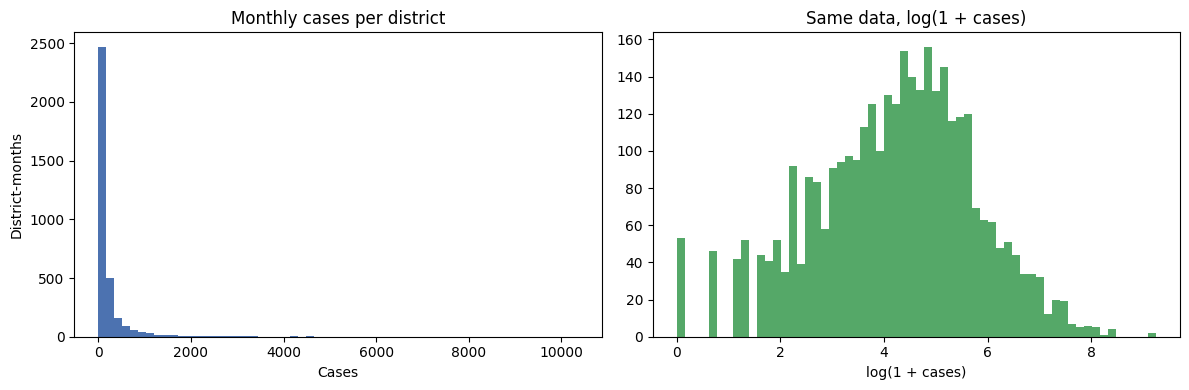

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df["cases"], bins=60, color="#4C72B0")
axes[0].set_title("Monthly cases per district")
axes[0].set_xlabel("Cases")
axes[0].set_ylabel("District-months")
axes[1].hist(np.log1p(df["cases"]), bins=60, color="#55A868")
axes[1].set_title("Same data, log(1 + cases)")
axes[1].set_xlabel("log(1 + cases)")
plt.tight_layout()
plt.show()

In [14]:
skew_check = df[numeric_cols].drop(columns=["year", "month"]).skew().sort_values(ascending=False)
skew_check.round(2).to_frame("skewness")

,skewness
mom_change_pct,24.87
cases,9.53
prev_month_incidence,9.50
prev_year_same_month_incidence,9.50
neighboring_district_cases_lag1,8.18
rolling_3month_avg,6.51
elevation,3.56
population_density,3.18
urban_pct,2.91
rainfall,1.54


Around 10% of district-months fall above the IQR fence. Nearly half of them are from 2017 and 2019, the two big outbreak years, and most of the rest are Colombo, Gampaha and Kandy, the most populated districts, where a few hundred cases is just an ordinary month. So these are real, not data errors, and they stay in. Removing them would remove exactly the months the model most needs to recognise.

What this means for the preprocessing:

- **Transformation:** the case-history features and **mom_change_pct** have very high skew. A `log1p` transform pulls the long tail in (right-hand chart). It is applied to those columns in the pipeline.
- **Scaling:** **RobustScaler** (median and IQR) instead of StandardScaler, since mean and standard deviation are dominated by the outbreak months.
- **Regression target:** the case count itself is a right-skewed count, which is a reason to give XGBoost a Poisson objective in Section 9 instead of plain squared error.

One honest note: Random Forest and XGBoost split on thresholds, so a monotonic transform or a scaler doesn't change which splits are possible. Section 5.4 tests this directly. They are still kept in the pipeline so the same preprocessed input can be fed to any model, including a linear one.

### <b>3.5 Correlation Between Features</b>

Two reasons to look at this before modelling. First, which features move with the case count at all. Second, Random Forest works best when its trees are *not* all built from the same few strong, closely related columns: if several features carry the same information, the trees end up looking alike (high inter-tree correlation), and averaging similar trees doesn't reduce the variance much.

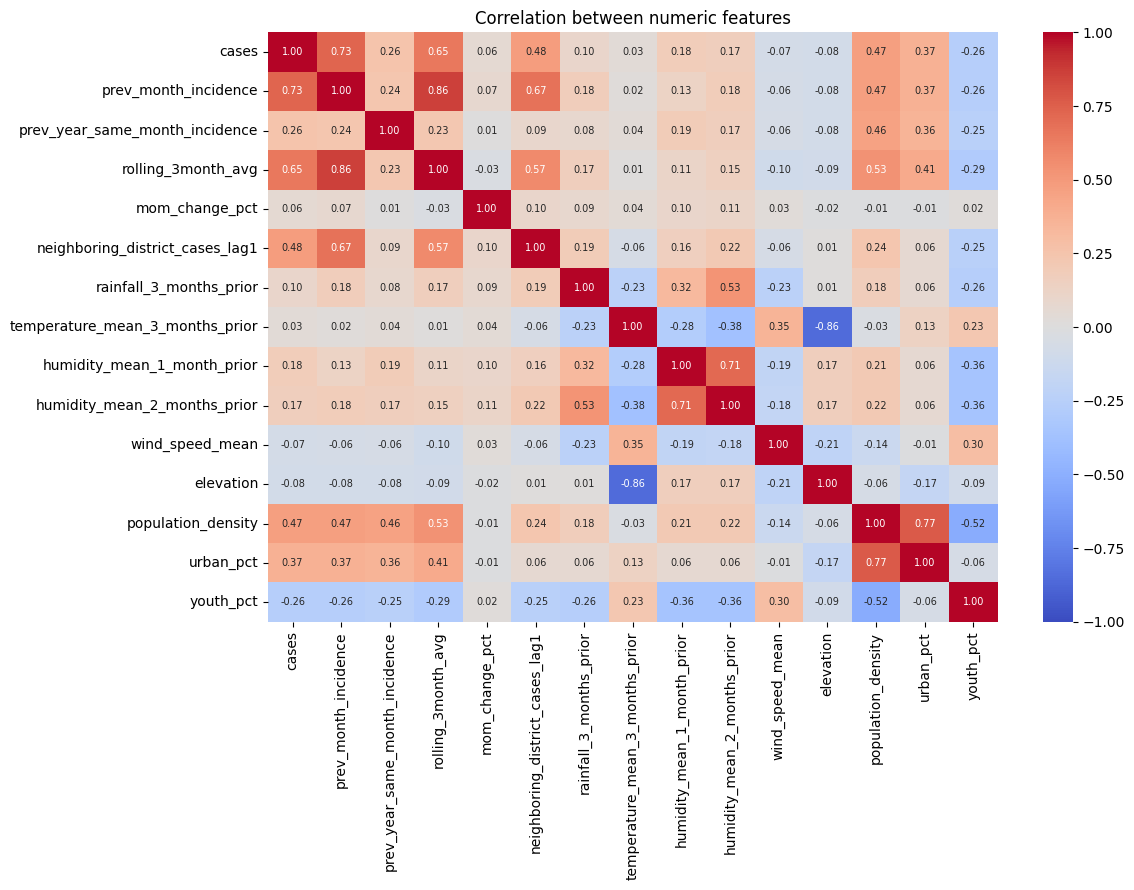

In [15]:
corr_columns = [
    "cases", "prev_month_incidence", "prev_year_same_month_incidence", "rolling_3month_avg", "mom_change_pct",
    "neighboring_district_cases_lag1", "rainfall_3_months_prior", "temperature_mean_3_months_prior",
    "humidity_mean_1_month_prior", "humidity_mean_2_months_prior", "wind_speed_mean", "elevation",
    "population_density", "urban_pct", "youth_pct",
]
corr_matrix = df[corr_columns].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, annot_kws={"size": 7})
plt.title("Correlation between numeric features")
plt.tight_layout()
plt.show()

In [16]:
print("Correlation with cases:")
print(corr_matrix["cases"].drop("cases").sort_values(ascending=False).round(3).to_string())

print("\nFeature pairs with |r| > 0.8:")
strong = [(a, b, round(corr_matrix.loc[a, b], 3))
          for i, a in enumerate(corr_columns[1:]) for b in corr_columns[i + 2:]
          if abs(corr_matrix.loc[a, b]) > 0.8]
for a, b, r in strong:
    print(f"  {a} ~ {b}: {r}")

Correlation with cases:
prev_month_incidence               0.732
rolling_3month_avg                 0.654
neighboring_district_cases_lag1    0.483
population_density                 0.474
urban_pct                          0.368
prev_year_same_month_incidence     0.255
humidity_mean_1_month_prior        0.184
humidity_mean_2_months_prior       0.167
rainfall_3_months_prior            0.098
mom_change_pct                     0.061
temperature_mean_3_months_prior    0.034
wind_speed_mean                   -0.072
elevation                         -0.082
youth_pct                         -0.260

Feature pairs with |r| > 0.8:
  prev_month_incidence ~ rolling_3month_avg: 0.861
  temperature_mean_3_months_prior ~ elevation: -0.859


What this shows:

- **Case history dominates.** Last month's cases (r = 0.73), the 3-month average (0.65) and the neighbouring districts' cases (0.48) are by far the strongest linear signals. **population_density** (0.47) and **urban_pct** (0.37) matter mainly because big, dense districts have more cases overall.
- **The weather columns barely correlate with cases on their own** (all below 0.2). That doesn't make them useless: the link between rain and dengue is delayed and non-linear (some rain creates breeding sites, very heavy rain can flush them out), which a correlation coefficient can't capture but a tree can. It does mean weather alone shouldn't be expected to carry the model.
- **Two pairs are strongly correlated with each other:** **prev_month_incidence** and **rolling_3month_avg** (0.86), which makes sense since last month is part of the 3-month average; and **temperature_mean_3_months_prior** and **elevation** (-0.86), because the hill country (Nuwara Eliya, Badulla, Kandy) is cooler.

Both pairs are kept. For the tree models, this is a reason not to let every split see every column (`max_features` below 1.0 in Section 6.3), so that some trees are built without the dominant case-history column and the forest stays diverse. For Logistic Regression, correlated inputs make the individual coefficients unstable, which is why it gets an L2 penalty in 6.2.

## <center><b>4. Defining the Targets</b></center>

The modelling table has the raw case count but no risk label, so the classification target has to be built.

### <b>4.1 WHO Endemic Channel</b>

A fixed national cut-off (say "more than 500 cases is an epidemic") makes no sense here. 500 cases is a normal month for Colombo and a disaster for Mullaitivu. The WHO Endemic Channel method (WHO 2009 dengue guidelines; Bortman 1999) compares each district against its own history instead:

- **Safety:** cases at or below the district's historical mean
- **Warning:** above the mean, but at or below mean + 2 standard deviations
- **Epidemic:** above mean + 2 standard deviations

The mean and standard deviation for a given year must only use years before it. If 2016's threshold was worked out from all years including 2017, the label for 2016 would quietly contain information from the future. So the baseline is an expanding window, and 2015 gets its baseline from the 2006 to 2014 weekly data.

### <b>4.2 Preparing the Weekly History</b>

In [17]:
table_districts = set(df["district"].unique())
weekly_districts = set(weekly_raw["district"].unique())

print("In weekly file but not in modelling table:", sorted(weekly_districts - table_districts))
print("In modelling table but not in weekly file:", sorted(table_districts - weekly_districts))

In weekly file but not in modelling table: ['Hambanthota', 'Kalmune', 'NuwaraEliya']
In modelling table but not in weekly file: ['Hambantota', 'Nuwara Eliya']


The weekly file spells some districts differently, and it also has **Kalmunai** as its own unit. Kalmunai is an RDHS area inside Ampara district (the health service splits Ampara into two reporting areas), not a separate district, so its cases are added to Ampara. The spellings are mapped to the names used in the modelling table.

In [18]:
district_fixes = {
    "Hambanthota": "Hambantota",
    "NuwaraEliya": "Nuwara Eliya",
    "Kalmune": "Ampara",
    "Kalmunai": "Ampara",
}
weekly = weekly_raw.copy()
weekly["district"] = weekly["district"].replace(district_fixes)

print("Still unmatched after fixing:", sorted(set(weekly["district"]) - table_districts) or "none")

Still unmatched after fixing: none


In [19]:
# monthly totals, using the week's start date to decide which month a week belongs to
weekly["week_start"] = pd.to_datetime(weekly["start.date"])
weekly["year"] = weekly["week_start"].dt.year
weekly["month"] = weekly["week_start"].dt.month
monthly_history = weekly.groupby(["district", "year", "month"], as_index=False)["cases"].sum()

pre_2015 = monthly_history[monthly_history["year"] < 2015]
print("Pre-2015 history:", pre_2015.shape, "| years", pre_2015["year"].min(), "-", pre_2015["year"].max())

Pre-2015 history: (2425, 4) | years 2006 - 2014


### <b>4.3 Building the Zone Label</b>

In [20]:
all_history = pd.concat([pre_2015, df[["district", "year", "month", "cases"]]], ignore_index=True)

yearly_baselines = []
for year in sorted(df["year"].unique()):
    # only years strictly before this one
    past = all_history[all_history["year"] < year]
    stats = past.groupby("district")["cases"].agg(baseline_mean="mean", baseline_std="std").reset_index()
    stats["year"] = year
    yearly_baselines.append(stats)

baselines = pd.concat(yearly_baselines, ignore_index=True)
df = df.merge(baselines, on=["district", "year"], how="left")
print("Rows without a baseline:", df["baseline_mean"].isna().sum())

Rows without a baseline: 0


In [21]:
zone_names = ["Safety", "Warning", "Epidemic"]

df["zone"] = np.select(
    [df["cases"] > df["baseline_mean"] + 2 * df["baseline_std"], df["cases"] > df["baseline_mean"]],
    [2, 1],
    default=0,
)
df["zone_name"] = df["zone"].map(dict(enumerate(zone_names)))

zone_counts = df["zone_name"].value_counts().reindex(zone_names)
(zone_counts.to_frame("rows").assign(pct=lambda t: (t["rows"] / len(df) * 100).round(1)))

,rows,pct
zone_name,,
Safety,1652,48.2
Warning,1392,40.6
Epidemic,381,11.1


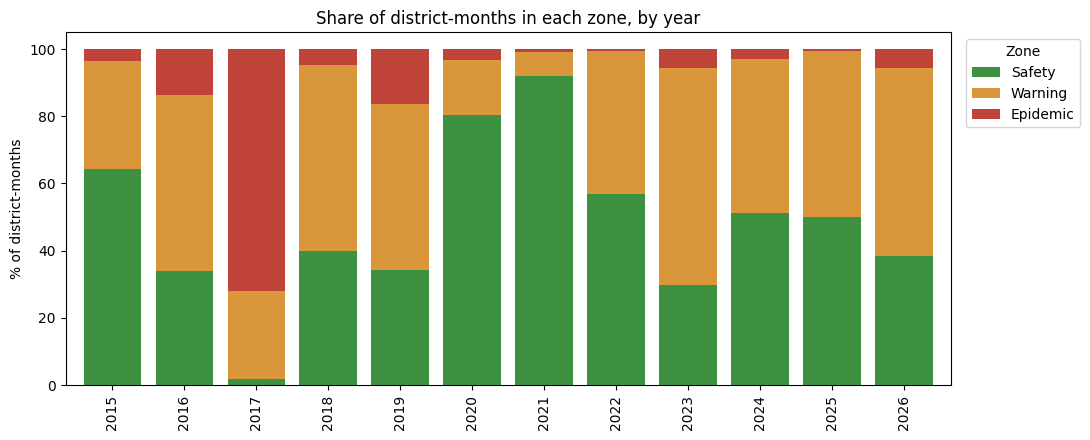

In [22]:
zone_colors = {"Safety": "#3F9142", "Warning": "#D9963A", "Epidemic": "#C0433A"}
share = pd.crosstab(df["year"], df["zone_name"], normalize="index").reindex(columns=zone_names) * 100

share.plot(kind="bar", stacked=True, figsize=(11, 4.5), color=[zone_colors[z] for z in zone_names], width=0.8)
plt.title("Share of district-months in each zone, by year")
plt.ylabel("% of district-months")
plt.xlabel("")
plt.legend(title="Zone", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

This is a good sanity check on the label. 2017 lights up as mostly Epidemic, and 2019 stands out too, which matches what actually happened in Sri Lanka. 2020 to 2022 are quiet (COVID-19 lockdowns changed both mosquito exposure and how many people went to hospital to get tested).

Epidemic is only about 11% of all rows, and much of that is 2017 alone. That imbalance will matter a lot later.

### <b>4.4 The Other Two Targets</b>

- **is_epidemic**: 1 if the zone is Epidemic, otherwise 0. Same information, but framed as "raise the alarm or not", which is how a health office would actually use it.
- **cases**: the raw count, for the regression task.

In [23]:
df["is_epidemic"] = (df["zone"] == 2).astype(int)
df[["district", "year", "month", "cases", "baseline_mean", "baseline_std", "zone_name", "is_epidemic"]].sample(6, random_state=random_state)

,district,year,month,cases,baseline_mean,baseline_std,zone_name,is_epidemic
790,Galle,2023,10,277,120.881,192.152,Warning,0
1411,Kandy,2018,6,477,222.752,477.920,Warning,0
2080,Matale,2017,2,72,42.413,58.736,Warning,0
1052,Hambantota,2022,10,69,63.077,83.662,Warning,0
443,Batticaloa,2017,9,135,52.397,68.629,Warning,0
2144,Matale,2022,6,189,67.171,123.420,Warning,0


## <center><b>5. Data Preparation</b></center>

### <b>5.1 Choosing the Features</b>

Not every column can be used. Anything describing the current month's outcome would leak the answer:

- **cases** is the regression target and the thing the zone was built from.
- **baseline_mean** and **baseline_std** are part of the label formula.
- Same-month **temperature_mean**, **rainfall** and **humidity_mean** are left out on purpose, since a forecast for next month wouldn't know next month's weather. The lagged versions are used instead.
- **year** is left out because the test years are beyond anything seen in training, so a tree can't do anything sensible with it.
- **sector_majority** is left out because it is just a coarse version of **urban_pct**.

In [24]:
numeric_features = [
    "rainfall_3_months_prior", "temperature_mean_3_months_prior",
    "humidity_mean_1_month_prior", "humidity_mean_2_months_prior",
    "wind_speed_mean", "elevation",
    "prev_month_incidence", "prev_year_same_month_incidence", "rolling_3month_avg",
    "mom_change_pct", "neighboring_district_cases_lag1",
    "population_density", "urban_pct", "youth_pct",
]
# heavily skewed columns from Section 3.4 that get a log1p transform
skewed_features = [
    "prev_month_incidence", "prev_year_same_month_incidence", "rolling_3month_avg",
    "neighboring_district_cases_lag1", "mom_change_pct", "population_density",
]
other_numeric = [c for c in numeric_features if c not in skewed_features]
categorical_features = ["district", "season"]
feature_columns = categorical_features + numeric_features

print("Features:", len(feature_columns), "| numeric", len(numeric_features), "| categorical", len(categorical_features))
print("mom_change_pct minimum:", df["mom_change_pct"].min())

Features: 16 | numeric 14 | categorical 2
mom_change_pct minimum: -100.0


**mom_change_pct** goes down to -100 (cases dropping to zero), and `log1p` is undefined below -1, so it needs a shift before the log. Since -100% is the lowest a percentage drop can go, shifting by 100 makes everything non-negative. That is folded into the transform function below.

### <b>5.2 Holding Out One Sample for Inference</b>

To test the saved model end to end, one unseen sample is run through it at the end. I'm taking the most recent month for Colombo, the district with the highest dengue burden in the country. It is removed now, before the train/test split, so no model or preprocessing step ever sees it.

In [25]:
df = df.sort_values(["year", "month", "district"]).reset_index(drop=True)

holdout_index = df[df["district"] == "Colombo"].index[-1]
holdout_row = df.loc[[holdout_index]].copy()
df = df.drop(index=holdout_index).reset_index(drop=True)

holdout_row[["district", "year", "month", "season", "cases", "zone_name"]]

,district,year,month,season,cases,zone_name
3404,Colombo,2026,5,SW_Monsoon,636,Safety


### <b>5.3 Time-Aware Train/Test Split</b>

This is time-series data for 25 districts. A random split would put, say, March 2024 in training and February 2024 in testing, letting the model learn from the future. Instead the split is by year: **2015 to 2023 for training, 2024 onwards for testing**. That's close to an 80/20 split by rows and it mimics real use: train on the past, predict what comes next.

In [26]:
train_df = df[df["year"] <= 2023].copy()
test_df = df[df["year"] >= 2024].copy()

X_train, X_test = train_df[feature_columns], test_df[feature_columns]
y_train, y_test = train_df["zone"], test_df["zone"]

print(f"Train: {len(train_df)} rows ({len(train_df) / len(df) * 100:.1f}%), years {train_df['year'].min()}-{train_df['year'].max()}")
print(f"Test:  {len(test_df)} rows ({len(test_df) / len(df) * 100:.1f}%), years {test_df['year'].min()}-{test_df['year'].max()}")
print("\nZone counts:")
pd.DataFrame({
    "train": train_df["zone_name"].value_counts(),
    "test": test_df["zone_name"].value_counts(),
}).reindex(zone_names)

Train: 2700 rows (78.9%), years 2015-2023
Test:  724 rows (21.1%), years 2024-2026

Zone counts:


,train,test
zone_name,,
Safety,1300,351
Warning,1037,355
Epidemic,363,18


The test period only has a small number of Epidemic months, because 2024 to 2026 were fairly normal years. That makes Epidemic metrics on the test set noisy (a few rows either way changes them a lot), which needs to be kept in mind when reading the results.

For choosing between models without touching the test set, I also set up **year-by-year validation folds** inside the training data: train on 2015-2019 and validate on 2020, then train on 2015-2020 and validate on 2021, and so on up to 2023. This is the time-series version of cross-validation.

In [27]:
def yearly_folds(frame, first_val_year=2020, last_val_year=2023):
    # expanding-window folds: train on all years before the validation year
    folds = []
    years = frame["year"].values
    for val_year in range(first_val_year, last_val_year + 1):
        train_idx = np.where(years < val_year)[0]
        val_idx = np.where(years == val_year)[0]
        folds.append((train_idx, val_idx))
    return folds


cv_folds = yearly_folds(train_df)
for (tr_idx, va_idx), val_year in zip(cv_folds, range(2020, 2024)):
    print(f"validate on {val_year}: train rows {len(tr_idx)}, validation rows {len(va_idx)}")

validate on 2020: train rows 1500, validation rows 300
validate on 2021: train rows 1800, validation rows 300
validate on 2022: train rows 2100, validation rows 300
validate on 2023: train rows 2400, validation rows 300


### <b>5.4 Preprocessing Pipeline</b>

Everything below is wrapped in a `ColumnTransformer` so it is fitted on the training rows only and applied the same way to the test rows and to the single held-out sample later.

- **Skewed numeric columns:** median imputation, then `log1p`, then RobustScaler
- **Other numeric columns:** median imputation, then RobustScaler
- **district and season:** most-frequent imputation, then one-hot encoding

In [28]:
def shifted_log1p(x):
    # +100 so that mom_change_pct (min -100) never goes below 0; harmless for the other count columns
    return np.log1p(np.asarray(x, dtype=float) + 100.0)


def build_preprocessor():
    skewed_pipe = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("log", FunctionTransformer(shifted_log1p, feature_names_out="one-to-one")),
        ("scale", RobustScaler()),
    ])
    numeric_pipe = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", RobustScaler()),
    ])
    categorical_pipe = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer([
        ("skewed", skewed_pipe, skewed_features),
        ("numeric", numeric_pipe, other_numeric),
        ("categorical", categorical_pipe, categorical_features),
    ])


preprocessor = build_preprocessor().fit(X_train)
X_train_prepared = preprocessor.transform(X_train)
print("Shape after preprocessing:", X_train_prepared.shape)
print("Any NaN left:", np.isnan(X_train_prepared).any())

Shape after preprocessing: (2700, 42)
Any NaN left: False


A quick experiment to confirm the claim from Section 3.4, that tree models don't care about scaling: the same small Random Forest trained on raw (only imputed) inputs and on fully transformed inputs.

In [29]:
# same column order as build_preprocessor, so the forest's random feature picks line up and only the transform differs
raw_only = ColumnTransformer([
    ("skewed", SimpleImputer(strategy="median"), skewed_features),
    ("numeric", SimpleImputer(strategy="median"), other_numeric),
    ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
])
small_rf = RandomForestClassifier(n_estimators=100, max_depth=8, min_samples_leaf=5, random_state=random_state, n_jobs=-1)

for label, prep in [("imputed only", raw_only), ("log + RobustScaler", build_preprocessor())]:
    pipe = Pipeline([("prep", prep), ("model", clone(small_rf))]).fit(X_train, y_train)
    print(f"{label:20s} train accuracy = {accuracy_score(y_train, pipe.predict(X_train)):.4f} | "
          f"test accuracy = {accuracy_score(y_test, pipe.predict(X_test)):.4f}")

imputed only         train accuracy = 0.7915 | test accuracy = 0.6809


log + RobustScaler   train accuracy = 0.7915 | test accuracy = 0.6809


Exactly the same result, on both training and test. Scaling and the log transform keep the order of the values, and a tree only ever asks "is this value above or below a cut-point", so the forest ends up making the same decisions either way. One detail matters for this comparison to be fair: both versions list the columns in the same order. Random Forest picks a random subset of column positions at each split, so a different order would give a different forest for reasons that have nothing to do with scaling.

So the preprocessing doesn't help the tree models, but it doesn't hurt them either. It's kept because it makes the pipeline usable with a scale-sensitive model, and the imputation part is still needed by Random Forest.

### <b>5.5 Data Leakage Checklist</b>

Data leakage is when information that wouldn't be available at prediction time sneaks into training, so the model looks better in testing than it will ever be in real use. The three common kinds, and how each is handled here:

| Type | What it means | How it is avoided in this notebook |
|---|---|---|
| **Target leakage** | A feature directly contains (or is computed from) the answer | Same-month cases and weather are excluded (5.1); **mom_change_pct** was checked in 3.2 to only use earlier months; the zone baseline only uses past years (4.3) |
| **Train-test contamination** | Test rows are seen during training | Time-based split (5.3): every test month is later than every training month, and the held-out Colombo row (5.2) is removed before anything else |
| **Preprocessing leakage** | Imputation, scaling or feature selection fitted on the full dataset | All preprocessing sits inside a `Pipeline` / `ColumnTransformer` (5.4), so it is refitted on the training rows only, in every fold |
| **Stacking leakage** | The meta-model learns from base-model predictions on rows those models were trained on | Stacking uses out-of-fold (cross-validated) predictions (Section 7) |

## <center><b>6. Building the Models: Weak Learners First, Then Ensembles</b></center>

The order is deliberate: start with single models (weak learners) and only move to ensembles if they hit a ceiling. So a single decision tree and a logistic regression come first (6.1, 6.2), then Random Forest and XGBoost are designed (6.3, 6.4), checked (6.5) and fine-tuned (6.6). Bagging, soft voting and stacking are added in the comparison in Section 7.

### <b>6.1 Weak Learner 1: Decision Tree</b>

A single tree grown with no limits memorises the training data, so its stopping rules have to be set: `criterion` (Gini or entropy), `max_depth`, `min_samples_split` and `min_samples_leaf`. Rather than guessing all four, they are searched with `GridSearchCV` over the yearly validation folds from 5.3.

In [30]:
dt_grid = {
    "model__criterion": ["gini", "entropy"],
    "model__max_depth": [3, 4, 5, 6, 8],
    "model__min_samples_split": [10, 20, 40],
    "model__min_samples_leaf": [5, 10, 20],
}
dt_search = GridSearchCV(
    Pipeline([("prep", build_preprocessor()), ("model", DecisionTreeClassifier(random_state=random_state))]),
    dt_grid, cv=cv_folds, scoring="f1_macro", n_jobs=-1, return_train_score=True,
).fit(X_train, y_train)

dt_best = {k.replace("model__", ""): v for k, v in dt_search.best_params_.items()}
print("Combinations tried:", len(dt_search.cv_results_["params"]))
print("Best decision tree settings:", dt_best)
print(f"Best CV macro F1: {dt_search.best_score_:.3f}")

Combinations tried: 90
Best decision tree settings: {'criterion': 'entropy', 'max_depth': 6, 'min_samples_leaf': 10, 'min_samples_split': 40}
Best CV macro F1: 0.497


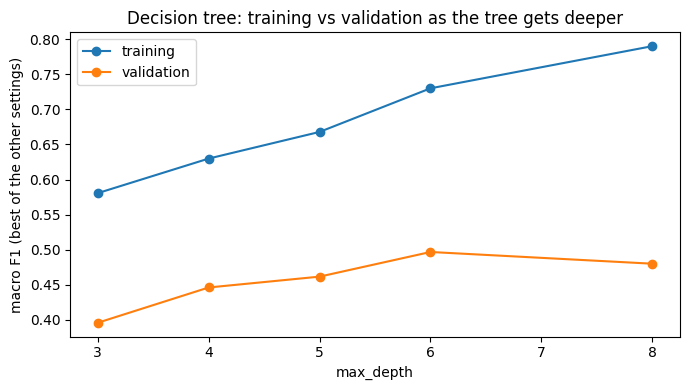

In [31]:
dt_results = pd.DataFrame(dt_search.cv_results_)
by_depth = dt_results.groupby("param_model__max_depth")[["mean_train_score", "mean_test_score"]].max()

plt.figure(figsize=(7, 4))
plt.plot(by_depth.index, by_depth["mean_train_score"], marker="o", label="training")
plt.plot(by_depth.index, by_depth["mean_test_score"], marker="o", label="validation")
plt.xlabel("max_depth")
plt.ylabel("macro F1 (best of the other settings)")
plt.title("Decision tree: training vs validation as the tree gets deeper")
plt.legend()
plt.tight_layout()
plt.show()

**Cost-complexity pruning** is the other way to control a tree: let it grow fully, then cut back the weakest branches. `ccp_alpha` sets how hard to prune (0 = no pruning). Below, a full tree is grown on 2015-2022 and scored on 2023 for a range of alpha values, with training and validation plotted together.

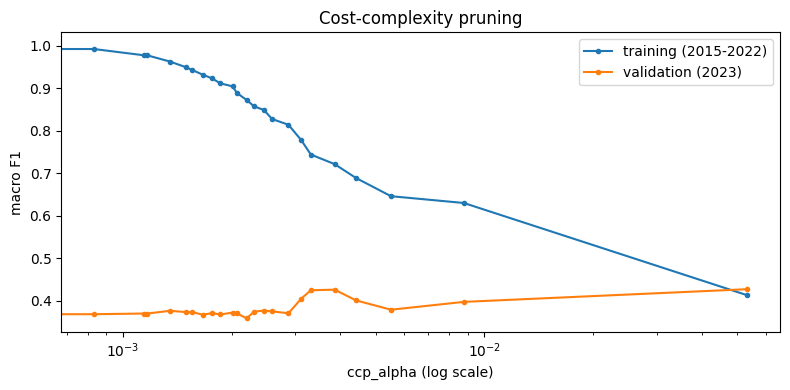

,ccp_alpha,leaves,train F1,validation F1
0,0.000,437,1.000,0.368
6,0.002,321,0.943,0.373
12,0.002,201,0.873,0.358
18,0.003,85,0.744,0.425
23,0.053,2,0.413,0.427


In [32]:
fit_part = train_df[train_df["year"] <= 2022]
val_part = train_df[train_df["year"] == 2023]
prune_prep = build_preprocessor().fit(fit_part[feature_columns])
Xf, Xv = prune_prep.transform(fit_part[feature_columns]), prune_prep.transform(val_part[feature_columns])

path = DecisionTreeClassifier(criterion=dt_best["criterion"], random_state=random_state).cost_complexity_pruning_path(Xf, fit_part["zone"])
alphas = np.unique(np.quantile(path.ccp_alphas[:-1], np.linspace(0, 1, 25)))
prune_rows = []
for a in alphas:
    t = DecisionTreeClassifier(criterion=dt_best["criterion"], ccp_alpha=a, random_state=random_state).fit(Xf, fit_part["zone"])
    prune_rows.append((a, t.get_n_leaves(),
                       f1_score(fit_part["zone"], t.predict(Xf), average="macro"),
                       f1_score(val_part["zone"], t.predict(Xv), average="macro")))
prune_table = pd.DataFrame(prune_rows, columns=["ccp_alpha", "leaves", "train F1", "validation F1"])

plt.figure(figsize=(8, 4))
plt.plot(prune_table["ccp_alpha"], prune_table["train F1"], marker=".", label="training (2015-2022)")
plt.plot(prune_table["ccp_alpha"], prune_table["validation F1"], marker=".", label="validation (2023)")
plt.xscale("log")
plt.xlabel("ccp_alpha (log scale)")
plt.ylabel("macro F1")
plt.title("Cost-complexity pruning")
plt.legend()
plt.tight_layout()
plt.show()
prune_table.iloc[[0, len(prune_table) // 4, len(prune_table) // 2, 3 * len(prune_table) // 4, -1]].round(4)

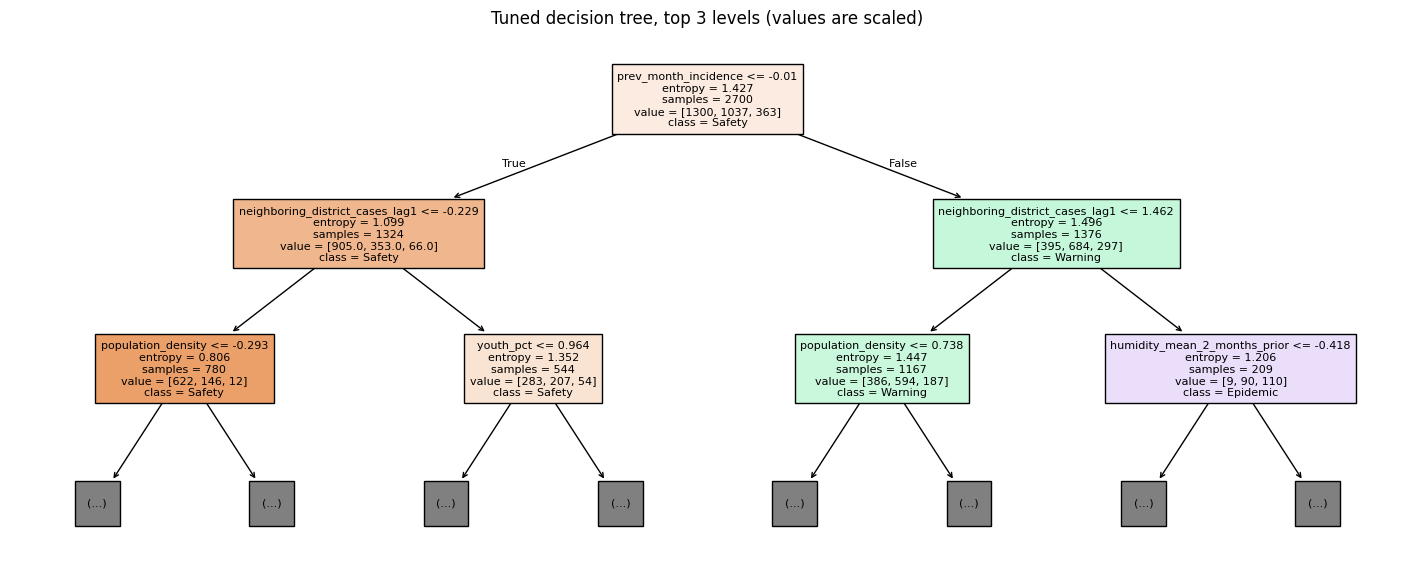

In [33]:
dt_tree = dt_search.best_estimator_.named_steps["model"]
dt_feature_names = [n.split("__", 1)[1] for n in dt_search.best_estimator_.named_steps["prep"].get_feature_names_out()]

plt.figure(figsize=(18, 7))
plot_tree(dt_tree, max_depth=2, feature_names=dt_feature_names, class_names=zone_names, filled=True, fontsize=8, impurity=True)
plt.title("Tuned decision tree, top 3 levels (values are scaled)")
plt.show()

The single tree tells the classic story: it can fit the training years very well but cannot carry that over to new years.

- In the grid search the best of 90 combinations is **entropy, max_depth 6, min_samples_split 40, min_samples_leaf 10**, with a cross-validation macro F1 of **0.497**. Gini vs entropy made little difference, as expected.
- The depth chart shows the classic overfitting pattern. Training F1 keeps climbing with depth (0.58 at depth 3 to 0.79 at depth 8), while validation F1 peaks at depth 6 (0.50) and then starts to fall.
- The pruning curve is even clearer. Unpruned, the tree has 437 leaves, fits the training years perfectly (F1 = 1.00) and scores only 0.37 on 2023; it has memorised individual district-months. Pruning down to about 85 leaves lifts validation to 0.43, and even a 2-leaf tree scores about the same on 2023. However much it is pruned, a single tree tops out somewhere around 0.43-0.50.
- The top of the tree already shows what matters: the first split is **prev_month_incidence**, then **neighboring_district_cases_lag1**, then **population_density**.

This ceiling is the reason to try ensembles: many trees combined should be able to keep the useful splits while averaging out the ones that only fit noise.

### <b>6.2 Weak Learner 2: Logistic Regression</b>

A linear model as the second weak learner. The settings that matter:

- `solver="lbfgs"`: a quasi-Newton method that approximates the Hessian instead of computing it, efficient for a small dense dataset and supports the multinomial (3-class) case directly
- `penalty="l2"` (Ridge): shrinks large coefficients, useful here because several features are strongly correlated (3.5)
- `C`: the inverse of the regularisation strength, searched below
- `max_iter=2000`: enough iterations to actually converge

In [34]:
lr_search = GridSearchCV(
    Pipeline([("prep", build_preprocessor()),
              ("model", LogisticRegression(solver="lbfgs", penalty="l2", max_iter=2000, random_state=random_state))]),
    {"model__C": [0.01, 0.1, 1.0, 10.0]}, cv=cv_folds, scoring="f1_macro", n_jobs=-1, return_train_score=True,
).fit(X_train, y_train)

lr_C = lr_search.best_params_["model__C"]
pd.DataFrame(lr_search.cv_results_)[["param_model__C", "mean_train_score", "mean_test_score", "std_test_score"]].round(3)

,param_model__C,mean_train_score,mean_test_score,std_test_score
0,0.01,0.634,0.458,0.079
1,0.10,0.692,0.516,0.083
2,1.00,0.711,0.530,0.066
3,10.00,0.714,0.529,0.063


`C = 1.0` is chosen (validation macro F1 0.530). Stronger regularisation (`C = 0.01`) underfits (0.458), and weaker regularisation (`C = 10`) gives no further gain. Worth noting already: Logistic Regression's gap between training and validation (0.71 vs 0.53) is much smaller than the deep tree's. It is a low-variance model, which matters when the test years differ from the training years.

### <b>6.3 Random Forest: Designing the Parameters</b>

No default values: every parameter that matters is set on purpose. The starting point is the data: about 2,700 training rows, 42 columns after one-hot encoding (14 numeric, 25 districts, 3 seasons), three unbalanced classes, strong year-to-year swings, and a test period that looks different from training (no 2017-style year in it). That points towards trees that are deliberately held back from memorising individual district-months.

| Parameter | Value | Reason |
|---|---|---|
| `n_estimators` | 500 | More trees never make a Random Forest overfit; they only make the average more stable and push the variance term down. The OOB error curve in 6.5 checks that 500 is past the point where it flattens. |
| `criterion` | `"gini"` | Gini and entropy produce very similar splits (6.1 showed little difference for the single tree); Gini is cheaper to compute, which matters with 500 trees. |
| `max_depth` | 10 | With ~2,700 rows a fully grown tree ends with leaves of 1 or 2 rows, which is memorising single district-months. Depth 10 still allows detailed interactions (district x season x recent cases). |
| `min_samples_split` | 10 | A node needs at least 10 district-months before it is allowed to split. |
| `min_samples_leaf` | 5 | Every leaf must cover at least 5 district-months, so no prediction rests on one odd month. With this and `min_samples_split=10`, a split always leaves at least 5 rows on each side. |
| `max_leaf_nodes` | None | Not used as a separate limit, because `max_depth` and `min_samples_leaf` already cap the tree size; a third limit on the same thing would only make the settings harder to reason about. |
| `max_features` | 0.4 | This is `m`, the number of columns tried at each split. Breiman's rule of thumb for classification is `m = sqrt(p)`, which here is sqrt(42) ≈ 6. The trade-off is that a smaller `m` makes trees less correlated with each other, but each tree gets weaker. Here the case-history columns are much stronger than the rest, and most of the 42 columns are one-hot district flags, so with only 6 candidates many splits would never get to see the useful columns at all. 40% (~16 columns) keeps the trees different from each other while still giving each split a fair chance. Section 6.6 tests sqrt against this. |
| `bootstrap`, `max_samples` | True, 0.8 | Each tree trains on a bootstrap sample the size of 80% of the rows (so roughly 55% distinct rows). This adds variety between trees and leaves a larger out-of-bag set. |
| `class_weight` | None | Explained below. |
| `oob_score` | True | Every row gets scored by the trees that didn't see it, a free validation estimate. |

On `class_weight`: reweighting Epidemic upwards would make the model call Epidemic far more often. For the 3-class model the probabilities should stay honest (they get averaged in the voting ensemble, and a health office should be able to read "30% chance of Epidemic" at face value), so no reweighting here. The binary model in Section 8 is where class weighting is used, because there the whole point is to catch Epidemic months.

In [35]:
rf_params = dict(
    n_estimators=500,
    criterion="gini",
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    max_leaf_nodes=None,
    max_features=0.4,
    bootstrap=True,
    max_samples=0.8,
    class_weight=None,
    oob_score=True,
    n_jobs=-1,
    random_state=random_state,
)

### <b>6.4 XGBoost: Designing the Parameters</b>

XGBoost is boosting, so unlike Random Forest, adding trees *can* overfit. The number of trees and the learning rate have to be decided together, and the regularisation terms matter.

| Parameter | Value | Reason |
|---|---|---|
| `learning_rate` | 0.03 | Each new tree's correction is shrunk to 3%, so the model creeps towards the answer instead of chasing noise in individual outbreak months. Slower to train, more stable. |
| `n_estimators` | early stopping | Trained with up to 2,000 trees on 2015-2022, stopped once the 2023 validation loss hasn't improved for 50 rounds. The best round is used for the final model. |
| `max_depth` | 4 | Boosting works best with weak learners. Depth 4 allows up to 4-way interactions (e.g. district x season x last month x rainfall), plenty for this problem. |
| `min_child_weight` | 3 | Minimum sum of Hessians (roughly, the amount of evidence) in a leaf. Stops leaves justified by one or two rows. |
| `subsample` | 0.8 | Each tree sees a random 80% of the rows (stochastic gradient boosting), which adds randomness and reduces overfitting. |
| `colsample_bytree` | 0.7 | Each tree sees 70% of the columns, so the model doesn't lean entirely on **prev_month_incidence**. |
| `reg_lambda` | 2.0 | L2 (Ridge) penalty on leaf weights, a bit stronger than usual, to smooth out extreme leaf values driven by outbreak spikes. |
| `reg_alpha` | 0.1 | Light L1 (Lasso) penalty, which can push useless leaf weights to exactly zero. |
| `gamma` | 0.1 | A split must reduce the loss by at least this much or it is pruned. |
| `objective` | `multi:softprob` | Returns a probability for each zone, which soft voting needs. |
| `tree_method` | `hist` | Histogram-based split finding, fast and standard for tabular data this size. |

In [36]:
xgb_shared_params = dict(
    learning_rate=0.03,
    max_depth=4,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.7,
    reg_lambda=2.0,
    reg_alpha=0.1,
    gamma=0.1,
    tree_method="hist",
    n_jobs=-1,
    random_state=random_state,
)

# early stopping: fit on 2015-2022, watch the loss on 2023
es_prep = build_preprocessor().fit(fit_part[feature_columns])

xgb_search = XGBClassifier(
    n_estimators=2000, objective="multi:softprob", eval_metric="mlogloss",
    early_stopping_rounds=50, **xgb_shared_params,
)
xgb_search.fit(
    es_prep.transform(fit_part[feature_columns]), fit_part["zone"],
    eval_set=[(es_prep.transform(fit_part[feature_columns]), fit_part["zone"]),
              (es_prep.transform(val_part[feature_columns]), val_part["zone"])],
    verbose=False,
)
xgb_n_estimators = xgb_search.best_iteration + 1
print("Best number of trees:", xgb_n_estimators)

Best number of trees: 143


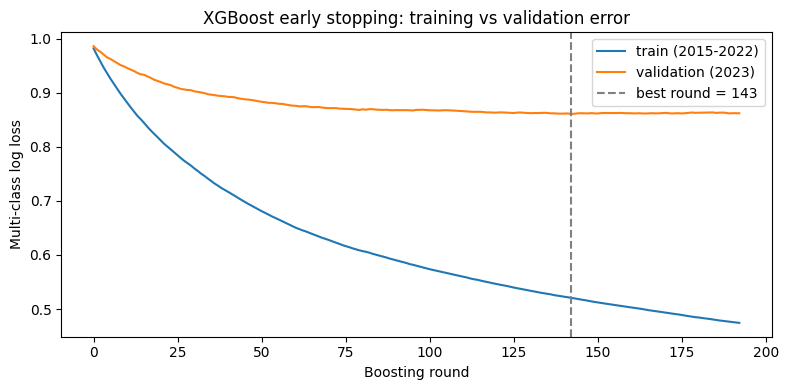

In [37]:
history = xgb_search.evals_result()
plt.figure(figsize=(8, 4))
plt.plot(history["validation_0"]["mlogloss"], label="train (2015-2022)")
plt.plot(history["validation_1"]["mlogloss"], label="validation (2023)")
plt.axvline(xgb_n_estimators - 1, color="grey", linestyle="--", label=f"best round = {xgb_n_estimators}")
plt.xlabel("Boosting round")
plt.ylabel("Multi-class log loss")
plt.title("XGBoost early stopping: training vs validation error")
plt.legend()
plt.tight_layout()
plt.show()

The training loss keeps falling the whole way, which is what boosting does: given enough rounds it will fit the training years almost perfectly. The 2023 validation loss drops quickly for the first 50 or so rounds, then flattens out and stops improving around round 143. Everything after that is the model learning details of 2015-2022 that don't carry over to a new year. So 143 trees at a learning rate of 0.03 is used from here on.

In [38]:
xgb_params = dict(n_estimators=xgb_n_estimators, objective="multi:softprob", eval_metric="mlogloss", **xgb_shared_params)

### <b>6.5 Checking the Design</b>

The values above were reasoned out, so they need checking. First, the classic Random Forest check: **out-of-bag error and test error against the number of trees**. Both should fall and then flatten out, and the OOB error should track the test error closely if it is a fair estimate. (The test set is only used here to draw the curve, not to choose anything.)

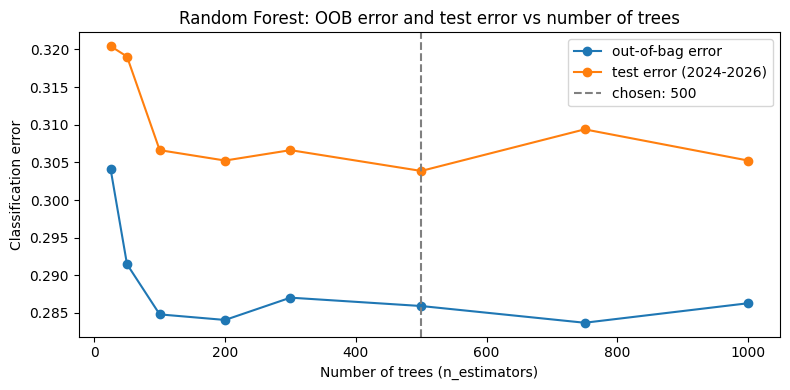

,trees,OOB error,test error
0,25,0.304,0.320
1,50,0.291,0.319
2,100,0.285,0.307
3,200,0.284,0.305
4,300,0.287,0.307
5,500,0.286,0.304
6,750,0.284,0.309
7,1000,0.286,0.305


In [39]:
X_train_prepared = preprocessor.transform(X_train)
X_test_prepared_for_curve = preprocessor.transform(X_test)

tree_counts = [25, 50, 100, 200, 300, 500, 750, 1000]
oob_errors, test_errors = [], []
for n in tree_counts:
    rf_check = RandomForestClassifier(**{**rf_params, "n_estimators": n}).fit(X_train_prepared, y_train)
    oob_errors.append(1 - rf_check.oob_score_)
    test_errors.append(1 - accuracy_score(y_test, rf_check.predict(X_test_prepared_for_curve)))

plt.figure(figsize=(8, 4))
plt.plot(tree_counts, oob_errors, marker="o", label="out-of-bag error")
plt.plot(tree_counts, test_errors, marker="o", label="test error (2024-2026)")
plt.axvline(500, color="grey", linestyle="--", label="chosen: 500")
plt.xlabel("Number of trees (n_estimators)")
plt.ylabel("Classification error")
plt.title("Random Forest: OOB error and test error vs number of trees")
plt.legend()
plt.tight_layout()
plt.show()
pd.DataFrame({"trees": tree_counts, "OOB error": oob_errors, "test error": test_errors}).round(4)

This is the shape the curve should have. Both errors drop quickly up to about 100 trees and then flatten out: OOB error settles around 0.285 and test error around 0.305. Adding trees beyond that changes almost nothing, but it never makes things worse either, which is the well-known Random Forest property (more trees reduce variance without overfitting). 500 trees is comfortably past the flat point.

The OOB error tracks the test error closely, about 0.02 lower throughout. So OOB works as a free validation set here. It is slightly optimistic because OOB rows come from the same training years, while the test years (2024-2026) are a genuinely new period.

Next, the effect of `max_features` (`m`, the number of columns each split may choose from) on the forest. A small `m` makes the trees more different from each other (lower inter-tree correlation) but each tree weaker; `m = 1.0` means every split sees every column, which is plain bagging. Each setting is scored with the OOB estimate and with the yearly folds.

In [40]:
mf_rows = []
for mf in ["sqrt", 0.2, 0.4, 0.6, 1.0]:
    rf_mf = RandomForestClassifier(**{**rf_params, "max_features": mf})
    oob = rf_mf.fit(X_train_prepared, y_train).oob_score_
    cv = cross_validate(Pipeline([("prep", build_preprocessor()), ("model", RandomForestClassifier(**{**rf_params, "max_features": mf, "oob_score": False}))]),
                        X_train, y_train, cv=cv_folds, scoring="f1_macro")["test_score"]
    columns_per_split = int(np.sqrt(X_train_prepared.shape[1])) if mf == "sqrt" else int(round(mf * X_train_prepared.shape[1]))
    mf_rows.append({"max_features": str(mf), "columns per split": columns_per_split, "OOB accuracy": oob,
                    "CV macro F1": cv.mean(), "CV std": cv.std()})
pd.DataFrame(mf_rows).round(3)

,max_features,columns per split,OOB accuracy,CV macro F1,CV std
0,sqrt,6,0.711,0.544,0.082
1,0.2,8,0.709,0.546,0.096
2,0.4,17,0.714,0.543,0.098
3,0.6,25,0.716,0.553,0.079
4,1.0,42,0.716,0.538,0.061


Every setting lands in the same place: OOB accuracy between 0.709 and 0.716, and cross-validation macro F1 between 0.538 and 0.553, with fold-to-fold standard deviations of 0.06-0.10. `max_features=0.6` is marginally best and plain bagging (1.0) marginally worst in cross-validation, which is the direction the theory predicts (more diverse trees average better), but the differences are far too small to matter. The designed 0.4 sits in the middle and is kept.

The effect is small because the useful signal is concentrated in a handful of columns (last month's cases, the 3-month average and the neighbours, Section 3.5). Whatever subset a split is given, the trees end up leaning on those few columns, so decorrelating the trees can only do so much.

The three ways of estimating performance also agree: Random Forest's OOB accuracy (0.714), its cross-validation accuracy on the yearly folds (0.694, Section 7.1) and its test accuracy (0.696, Section 7.2) are within two points of each other. OOB is the most optimistic, because its rows come from the same years the trees trained on.

Second, validation scores across a range of `max_depth` values for both models, using the yearly folds, with training scores alongside to see where overfitting starts.

In [41]:
depth_rows = []
for depth in [2, 3, 4, 6, 8, 10, 14, None]:
    rf_d = Pipeline([("prep", build_preprocessor()), ("model", RandomForestClassifier(**{**rf_params, "max_depth": depth, "oob_score": False}))])
    rf_cv = cross_validate(rf_d, X_train, y_train, cv=cv_folds, scoring="f1_macro", return_train_score=True)
    row = {"max_depth": str(depth), "RF train F1": rf_cv["train_score"].mean(), "RF validation F1": rf_cv["test_score"].mean()}
    if depth is not None and depth <= 10:
        xgb_d = Pipeline([("prep", build_preprocessor()), ("model", XGBClassifier(**{**xgb_params, "max_depth": depth}))])
        xgb_cv = cross_validate(xgb_d, X_train, y_train, cv=cv_folds, scoring="f1_macro", return_train_score=True)
        row.update({"XGB train F1": xgb_cv["train_score"].mean(), "XGB validation F1": xgb_cv["test_score"].mean()})
    depth_rows.append(row)

depth_table = pd.DataFrame(depth_rows)
depth_table.round(3)

,max_depth,RF train F1,RF validation F1,XGB train F1,XGB validation F1
0,2,0.565,0.438,0.693,0.524
1,3,0.636,0.498,0.756,0.521
2,4,0.687,0.533,0.814,0.526
3,6,0.775,0.547,0.912,0.540
4,8,0.832,0.553,0.959,0.542
5,10,0.868,0.543,0.980,0.535
6,14,0.884,0.557,NaN,NaN
7,None,0.886,0.559,NaN,NaN


A few things stand out.

- **Random Forest:** the gap between train and validation F1 grows steadily with depth, from about 0.13 at depth 2 to 0.33 with no limit. Validation F1 does creep up a little with deeper trees (0.543 at depth 10 vs 0.559 unlimited), but that 0.016 difference is much smaller than the spread between folds (around 0.09, see 6.6 and 7.1), so it can't really be told apart from noise. Depth 10 is kept: it performs about the same as unlimited trees, overfits less, and makes a much smaller model file.
- **XGBoost:** shallower trees overfit far less (train F1 0.81 at depth 4 against 0.98 at depth 10), while validation F1 barely moves between depth 4 and 8 (0.526 to 0.542). Again the differences are within noise, so the shallower, more regularised choice of 4 stands. Note that the number of trees was tuned for depth 4, so the deeper settings are slightly disadvantaged here.
- The out-of-bag curve flattens out after about 100 trees, so 500 is more than enough. The extra trees cost only training time and don't hurt.
- Every model has a validation macro F1 in the low to mid 0.5s across every setting. That ceiling comes from the data (how predictable next month's zone is from these features), not from the hyperparameters. Tuning further would be chasing noise.

### <b>6.6 Fine-Tuning with GridSearchCV</b>

Finally, a grid search around the designed values, to see whether nearby settings do clearly better. The grids are deliberately small and centred on the design, since the point is to check the reasoning, not to try every combination. The rule: only switch to the tuned settings if their cross-validation score beats the designed one by more than the fold-to-fold standard deviation. Otherwise the difference is noise and the designed (more conservative) settings stay.

In [42]:
def designed_cv_score(model):
    pipe = Pipeline([("prep", build_preprocessor()), ("model", model)])
    s = cross_validate(pipe, X_train, y_train, cv=cv_folds, scoring="f1_macro")["test_score"]
    return s.mean(), s.std()


rf_tune = GridSearchCV(
    Pipeline([("prep", build_preprocessor()), ("model", RandomForestClassifier(**{**rf_params, "oob_score": False, "n_jobs": -1}))]),
    {"model__max_depth": [8, 10, 14], "model__min_samples_leaf": [3, 5, 10], "model__max_features": ["sqrt", 0.4, 0.6]},
    cv=cv_folds, scoring="f1_macro", n_jobs=1,
).fit(X_train, y_train)

xgb_tune = GridSearchCV(
    Pipeline([("prep", build_preprocessor()), ("model", XGBClassifier(**{**xgb_params, "n_jobs": 1}))]),
    {"model__max_depth": [3, 4, 6], "model__min_child_weight": [1, 3, 5], "model__reg_lambda": [1.0, 2.0, 5.0]},
    cv=cv_folds, scoring="f1_macro", n_jobs=-1,
).fit(X_train, y_train)

tuning_rows = []
for name, search, designed_model in [("Random Forest", rf_tune, RandomForestClassifier(**{**rf_params, "oob_score": False})),
                                     ("XGBoost", xgb_tune, XGBClassifier(**xgb_params))]:
    d_mean, d_std = designed_cv_score(designed_model)
    best_std = pd.DataFrame(search.cv_results_).loc[search.best_index_, "std_test_score"]
    tuning_rows.append({
        "Model": name,
        "Designed CV F1": d_mean, "Designed std": d_std,
        "Tuned CV F1": search.best_score_, "Tuned std": best_std,
        "Gain": search.best_score_ - d_mean,
        "Tuned settings": {k.replace("model__", ""): v for k, v in search.best_params_.items()},
        "Switch?": (search.best_score_ - d_mean) > d_std,
    })
tuning_table = pd.DataFrame(tuning_rows)
tuning_table.round(3)

,Model,Designed CV F1,Designed std,Tuned CV F1,Tuned std,Gain,Tuned settings,Switch?
0,Random Forest,0.543,0.098,0.584,0.091,0.041,"{'max_depth': 14, 'max_features': 'sqrt', 'min...",False
1,XGBoost,0.526,0.082,0.542,0.080,0.016,"{'max_depth': 4, 'min_child_weight': 1, 'reg_l...",False


In [43]:
# apply the rule: only take the tuned settings when the gain is bigger than the fold-to-fold noise
if tuning_table.loc[0, "Switch?"]:
    rf_params.update(tuning_table.loc[0, "Tuned settings"])
if tuning_table.loc[1, "Switch?"]:
    xgb_params.update(tuning_table.loc[1, "Tuned settings"])
    xgb_shared_params.update({k: v for k, v in tuning_table.loc[1, "Tuned settings"].items()})

for _, row in tuning_table.iterrows():
    print(f"{row['Model']} best grid settings: {row['Tuned settings']}")
print()
print("Random Forest settings used from here:", {k: rf_params[k] for k in ["max_depth", "min_samples_leaf", "max_features"]})
print("XGBoost settings used from here:", {k: xgb_params[k] for k in ["max_depth", "min_child_weight", "reg_lambda"]})

Random Forest best grid settings: {'max_depth': 14, 'max_features': 'sqrt', 'min_samples_leaf': 5}
XGBoost best grid settings: {'max_depth': 4, 'min_child_weight': 1, 'reg_lambda': 2.0}

Random Forest settings used from here: {'max_depth': 10, 'min_samples_leaf': 5, 'max_features': 0.4}
XGBoost settings used from here: {'max_depth': 4, 'min_child_weight': 3, 'reg_lambda': 2.0}


Both grid searches found settings with a higher average cross-validation score than the designed ones, but in both cases the gain is well inside the fold-to-fold noise:

- **Random Forest:** the best grid point was `max_depth=14, max_features="sqrt", min_samples_leaf=5`, giving 0.584 against 0.543 for the design. The gain of 0.041 is less than half the standard deviation across folds (0.098). Interestingly, `"sqrt"` is Breiman's own rule of thumb for `m`, so the grid didn't confirm the argument in 6.3 for using more columns per split. It didn't clearly reject it either.
- **XGBoost:** the best grid point only changed `min_child_weight` from 3 to 1 (0.542 vs 0.526), a gain of 0.016 against a standard deviation of 0.082.

Following the rule, the designed settings are kept. With only four validation years (one of them, 2021, with almost no Epidemic months) a 0.04 difference can come from a single fold, and picking the top of a grid on so few folds risks tuning to those particular years. The more conservative settings (shallower RF trees, larger XGBoost leaves) are also the safer choice for years that look different from training. This is a judgement call, and with more data (for example weekly instead of monthly) the tuned settings would be worth revisiting.

## <center><b>7. Main Task: Safety / Warning / Epidemic</b></center>

Every model uses the same preprocessing, in order of increasing complexity:

1. **Naive baseline:** always predict each district's most common zone from the training years. Any model that can't beat this isn't learning anything useful.
2. **Decision Tree** (weak learner, settings from 6.1)
3. **Logistic Regression** (weak learner, settings from 6.2)
4. **Bagging:** 500 decision trees on bootstrap samples, every tree sees all features (same depth and leaf limits as the Random Forest, so the only difference from RF is the random feature subsets)
5. **Random Forest** (6.3, 6.6)
6. **XGBoost** (6.4, 6.6)
7. **Soft voting** of RF and XGBoost: average their predicted probabilities and pick the highest
8. **Stacking:** a Logistic Regression meta-model learns how much to trust each model's probabilities. This is cross-validated stacking: the meta-model's training inputs are out-of-fold predictions, so it never learns from a model scoring rows it was trained on. `StackingClassifier` needs folds that cover every training row, which the expanding yearly folds don't, so it uses 5 consecutive (unshuffled) blocks of the time-ordered training data.

In [44]:
rf_model = RandomForestClassifier(**rf_params)
xgb_model = XGBClassifier(**xgb_params)

classifiers = {
    "Decision Tree": DecisionTreeClassifier(**dt_best, random_state=random_state),
    "Logistic Regression": LogisticRegression(solver="lbfgs", penalty="l2", C=lr_C, max_iter=2000, random_state=random_state),
    "Bagging (500 trees, all features)": BaggingClassifier(
        estimator=DecisionTreeClassifier(criterion="gini", max_depth=rf_params["max_depth"],
                                         min_samples_split=10, min_samples_leaf=rf_params["min_samples_leaf"]),
        n_estimators=500, max_samples=0.8, bootstrap=True, max_features=1.0, n_jobs=-1, random_state=random_state),
    "Random Forest": rf_model,
    "XGBoost": xgb_model,
    "Soft Voting (RF + XGB)": VotingClassifier(
        estimators=[("rf", clone(rf_model)), ("xgb", clone(xgb_model))], voting="soft", weights=[1, 1], n_jobs=1),
    "Stacking (RF + XGB -> LogReg)": StackingClassifier(
        estimators=[("rf", clone(rf_model)), ("xgb", clone(xgb_model))],
        final_estimator=LogisticRegression(C=1.0, max_iter=2000),
        stack_method="predict_proba", cv=KFold(n_splits=5, shuffle=False), n_jobs=1),
}

### <b>7.1 Choosing on the Validation Folds</b>

Every model is first scored on the yearly folds (training data only). The final choice is based on this, so the test set stays untouched until the end. The main metric is **macro F1** (the average F1 across the three zones), because plain accuracy would reward a model that ignores the rare Epidemic class.

The rule for choosing: with only four folds, a model only counts as clearly better if it is ahead by more than the fold-to-fold standard deviation. If the top models are closer than that, they are treated as tied, and the soft voting ensemble is used, since it doesn't depend on either single model happening to suit the test years.

In [45]:
cv_rows = []
for name, model in classifiers.items():
    pipe = Pipeline([("prep", build_preprocessor()), ("model", model)])
    scores = cross_validate(pipe, X_train, y_train, cv=cv_folds, scoring=["accuracy", "f1_macro"], return_train_score=True)
    cv_rows.append({
        "Model": name,
        "CV train macro F1": scores["train_f1_macro"].mean(),
        "CV accuracy": scores["test_accuracy"].mean(),
        "CV macro F1": scores["test_f1_macro"].mean(),
        "CV macro F1 (std)": scores["test_f1_macro"].std(),
    })

cv_results = pd.DataFrame(cv_rows).sort_values("CV macro F1", ascending=False).reset_index(drop=True)
cv_results.round(3)

,Model,CV train macro F1,CV accuracy,CV macro F1,CV macro F1 (std)
0,Stacking (RF + XGB -> LogReg),0.756,0.712,0.568,0.095
1,Random Forest,0.868,0.694,0.543,0.098
2,"Bagging (500 trees, all features)",0.877,0.681,0.538,0.061
3,Logistic Regression,0.711,0.713,0.530,0.066
4,Soft Voting (RF + XGB),0.838,0.698,0.530,0.085
5,XGBoost,0.814,0.693,0.526,0.082
6,Decision Tree,0.680,0.661,0.497,0.071


The ranking in cross-validation:

- **Stacking** comes out on top (0.568), followed by **Random Forest** (0.543), **Bagging** (0.538), **Logistic Regression** and **soft voting** (both 0.530), and **XGBoost** (0.526). The **Decision Tree** is clearly last (0.497).
- The spread between all the models except the Decision Tree is 0.04, while the standard deviation across folds is 0.06 to 0.10 for every model. By the rule above, that's a tie: four folds aren't enough to say any one of these is better. The fold-to-fold swing is large because each validation year is so different (2020 and 2021 had almost no Epidemic months).
- **Bagging vs Random Forest** is the cleanest comparison in the table, since they differ only in Random Forest's random feature subsets. Random Forest is very slightly ahead (0.543 vs 0.538), consistent with the idea that less correlated trees average better, but the difference is small.
- The training scores show the variance side: Bagging and Random Forest reach about 0.87 macro F1 on the folds they trained on, against 0.71 for Logistic Regression. The tree ensembles fit their training years far more closely, without being better on the validation years.

So the deployed zone model is the **soft voting ensemble**, per the rule. The test set below is still used to report how every model does on years it has never seen.

### <b>7.2 Final Training and Test Results</b>

In [46]:
district_usual_zone = train_df.groupby("district")["zone"].agg(lambda s: s.mode()[0])
baseline_pred = test_df["district"].map(district_usual_zone).values


def zone_scores(name, y_true, pred, train_acc=np.nan):
    return {
        "Model": name,
        "Train accuracy": train_acc,
        "Test accuracy": accuracy_score(y_true, pred),
        "Balanced accuracy": balanced_accuracy_score(y_true, pred),
        "Test macro F1": f1_score(y_true, pred, average="macro"),
        "Epidemic recall": recall_score(y_true, pred, labels=[2], average="macro", zero_division=0),
        "Epidemic F1": f1_score(y_true, pred, labels=[2], average="macro", zero_division=0),
    }


fitted_classifiers = {}
test_rows = [zone_scores("Naive baseline (district's usual zone)", y_test, baseline_pred)]
for name, model in classifiers.items():
    pipe = Pipeline([("prep", build_preprocessor()), ("model", clone(model))]).fit(X_train, y_train)
    fitted_classifiers[name] = pipe
    test_rows.append(zone_scores(name, y_test, pipe.predict(X_test), accuracy_score(y_train, pipe.predict(X_train))))

test_results = pd.DataFrame(test_rows)
test_results["Train-test gap"] = test_results["Train accuracy"] - test_results["Test accuracy"]
test_results.round(3)

,Model,Train accuracy,Test accuracy,Balanced accuracy,Test macro F1,Epidemic recall,Epidemic F1,Train-test gap
0,Naive baseline (district's usual zone),NaN,0.510,0.349,0.320,0.000,0.000,NaN
1,Decision Tree,0.702,0.612,0.471,0.461,0.167,0.128,0.090
2,Logistic Regression,0.720,0.709,0.643,0.621,0.500,0.429,0.011
3,"Bagging (500 trees, all features)",0.864,0.693,0.562,0.571,0.278,0.312,0.170
4,Random Forest,0.857,0.696,0.546,0.553,0.222,0.250,0.161
5,XGBoost,0.796,0.702,0.567,0.581,0.278,0.323,0.094
6,Soft Voting (RF + XGB),0.826,0.693,0.544,0.559,0.222,0.276,0.133
7,Stacking (RF + XGB -> LogReg),0.755,0.671,0.512,0.508,0.167,0.150,0.084


In [47]:
print("Random Forest out-of-bag accuracy:", round(fitted_classifiers["Random Forest"].named_steps["model"].oob_score_, 3))

Random Forest out-of-bag accuracy: 0.714


Every model beats the naive baseline (51% accuracy, macro F1 0.32, and it never predicts Epidemic). The ordering among the models is not what cross-validation suggested, though:

- **Logistic Regression is the best model on the test years**: highest macro F1 (0.621), highest balanced accuracy (0.643), the most Epidemic months caught (9 of 18, recall 0.50) and almost no train-test gap (0.011).
- **XGBoost** is the best tree-based model (70.2% accuracy, macro F1 0.581) with the smallest gap of the tree ensembles (0.094), thanks to its regularisation and early stopping.
- **Random Forest** and **Bagging** are close to each other (macro F1 0.553 and 0.571). Both have the largest train-test gaps (0.16-0.17) even with depth and leaf limits. Random Forest's out-of-bag accuracy (0.714) is close to its test accuracy, so OOB is honest; it's the training score that is misleading.
- **Soft voting** sits between RF and XGBoost, as averaging two similar models usually does.
- **Stacking** won cross-validation but comes last of the ensembles on test, with the lowest Epidemic recall (0.167). Its meta-model learns how to weight RF and XGBoost from the training years, which include 2017's huge outbreak; with so few Epidemic months in the test period, those weights don't transfer.
- The **Decision Tree** is the weakest learned model (macro F1 0.461), as expected after 6.1.

Why would the simplest model do best on 2024-2026? These were fairly normal years, and in normal years the zone follows a smooth pattern: if last month (and the neighbours) were high, this month is likely to be high. After the log transform that relationship is close to linear, which suits Logistic Regression. The tree ensembles learned sharper, more specific rules from the outbreak years (2017, 2019), which fit training well but help less in a quiet period. In bias-variance terms, the ensembles bought lower bias they didn't need here, at the cost of more variance.

This shouldn't be over-read. Section 7.4 checks whether the gap is real, and with only 18 Epidemic months in the test period, one or two rows either way changes the Epidemic columns a lot. It is a good reminder that ensembles are not automatically better, and that a simpler model is fine if it performs as well.

### <b>7.3 Where the Mistakes Are</b>

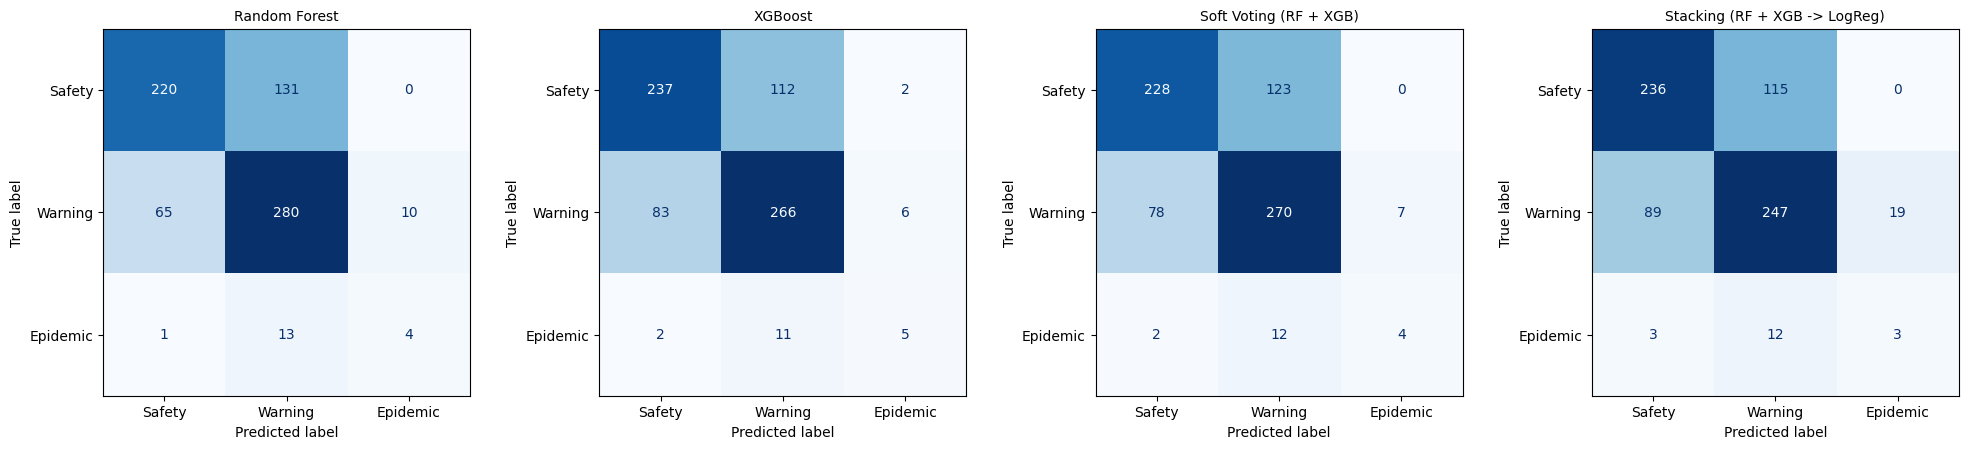

In [48]:
ensemble_names = ["Random Forest", "XGBoost", "Soft Voting (RF + XGB)", "Stacking (RF + XGB -> LogReg)"]
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, name in zip(axes, ensemble_names):
    ConfusionMatrixDisplay.from_predictions(
        y_test, fitted_classifiers[name].predict(X_test), display_labels=zone_names, ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name, fontsize=10)
plt.tight_layout()
plt.show()

In [49]:
for name in ["Random Forest", "XGBoost"]:
    print(f"--- {name} ---")
    print(classification_report(y_test, fitted_classifiers[name].predict(X_test), target_names=zone_names, digits=3))

--- Random Forest ---
              precision    recall  f1-score   support

      Safety      0.769     0.627     0.691       351
     Warning      0.660     0.789     0.719       355
    Epidemic      0.286     0.222     0.250        18

    accuracy                          0.696       724
   macro avg      0.572     0.546     0.553       724
weighted avg      0.704     0.696     0.694       724

--- XGBoost ---
              precision    recall  f1-score   support

      Safety      0.736     0.675     0.704       351
     Warning      0.684     0.749     0.715       355
    Epidemic      0.385     0.278     0.323        18

    accuracy                          0.702       724
   macro avg      0.601     0.567     0.581       724
weighted avg      0.702     0.702     0.700       724



The confusion matrices tell the same story for all four models. Almost all the errors are between neighbouring zones: Safety mixed up with Warning, or Warning with Epidemic. A Safety month is almost never predicted as Epidemic or the other way around. That is reassuring, because the boundary between Safety and Warning is literally the district's mean, so a month sitting just above or below it is close to a coin flip.

Random Forest leans towards Warning (high Warning recall of 0.79, lower Safety recall of 0.63), while XGBoost is more balanced between the two. For a health office, calling a Safety month "Warning" is a cheap mistake (some extra inspections). Calling an Epidemic month "Warning" is the expensive one, and that's what happens to most of the 18 Epidemic months.

In [50]:
rf_pred_test = fitted_classifiers["Random Forest"].predict(X_test)
xgb_pred_test = fitted_classifiers["XGBoost"].predict(X_test)
both_wrong = (rf_pred_test != y_test.values) & (xgb_pred_test != y_test.values)

print(f"Test months misclassified by both RF and XGBoost: {both_wrong.sum()} of {len(y_test)}")
print("\nBy actual zone (share of that zone that both models got wrong):")
print((pd.Series(both_wrong, index=test_df.index).groupby(test_df["zone_name"]).mean().reindex(zone_names) * 100).round(1).to_string())
print("\nMost common mistake pairs (actual -> both predicted the same wrong zone):")
same_wrong = both_wrong & (rf_pred_test == xgb_pred_test)
pairs = pd.Series([f"{zone_names[a]} -> {zone_names[p]}" for a, p in zip(y_test.values[same_wrong], rf_pred_test[same_wrong])])
print(pairs.value_counts().to_string())

Test months misclassified by both RF and XGBoost: 190 of 724

By actual zone (share of that zone that both models got wrong):
zone_name
Safety      31.6
Warning     18.6
Epidemic    72.2

Most common mistake pairs (actual -> both predicted the same wrong zone):
Safety -> Warning      109
Warning -> Safety       61
Epidemic -> Warning     11
Warning -> Epidemic      5
Epidemic -> Safety       1


Random Forest and XGBoost are both wrong on 190 of the 724 test months (26%), and when they are both wrong they nearly always make the *same* mistake:

- **Safety → Warning (109 months)** is the most common shared error. In the quiet 2024-2026 period, both models call many normal months "Warning", having learned from training years that were generally busier.
- **Warning → Safety (61)** is the reverse, mostly months sitting close to the district's mean line.
- **72% of the real Epidemic months are missed by both models**, almost all of them called Warning (11 months).

This explains why soft voting barely changes anything. Averaging only helps when the members make *different* errors, and here the two tree ensembles share most of theirs. Adding a different kind of model (such as Logistic Regression, or a time-series model) is more likely to help than adding more trees.

### <b>7.3b Performance by District</b>

An overall score can hide districts where the model works badly. The deployed soft voting model's test accuracy per district:

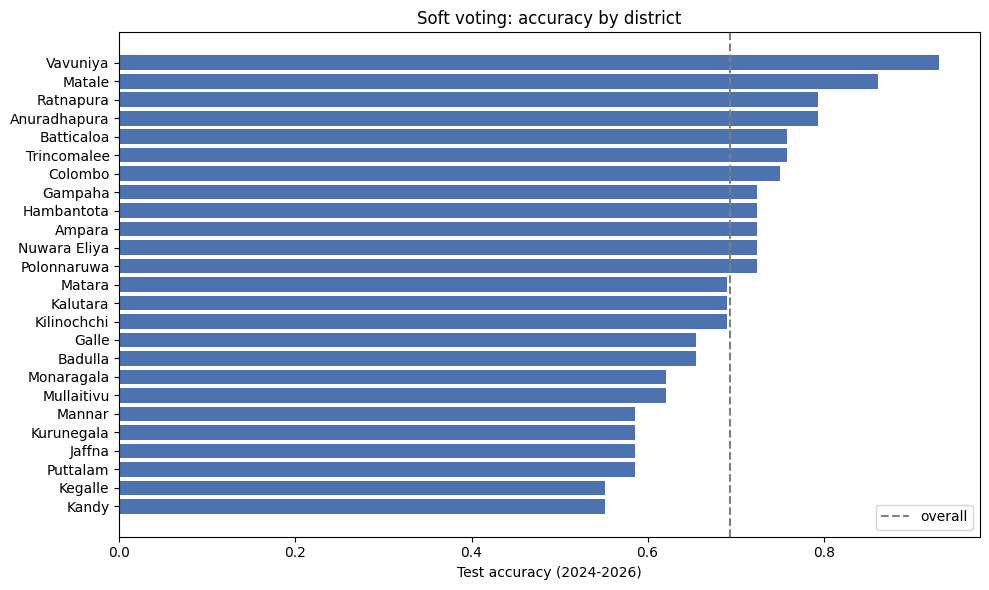

,test_months,accuracy,epidemic_months
district,,,
Kandy,29,0.552,0
Kegalle,29,0.552,0
Puttalam,29,0.586,0
Jaffna,29,0.586,2
Kurunegala,29,0.586,0
Batticaloa,29,0.759,0
Anuradhapura,29,0.793,1
Ratnapura,29,0.793,2
Matale,29,0.862,1


In [51]:
vote_pred_test = fitted_classifiers["Soft Voting (RF + XGB)"].predict(X_test)
by_district = (pd.DataFrame({"district": test_df["district"].values, "correct": vote_pred_test == y_test.values,
                             "epidemic_months": (y_test.values == 2)})
               .groupby("district").agg(test_months=("correct", "size"), accuracy=("correct", "mean"), epidemic_months=("epidemic_months", "sum"))
               .sort_values("accuracy"))

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(by_district.index, by_district["accuracy"], color="#4C72B0")
ax.axvline((vote_pred_test == y_test.values).mean(), color="grey", linestyle="--", label="overall")
ax.set_xlabel("Test accuracy (2024-2026)")
ax.set_title("Soft voting: accuracy by district")
ax.legend()
plt.tight_layout()
plt.show()
pd.concat([by_district.head(5), by_district.tail(5)]).round(3)

Accuracy varies a lot by district, from about 55% (Kandy, Kegalle) up to 93% (Vavuniya). The weakest districts (Kandy, Kegalle, Puttalam, Jaffna, Kurunegala) are all around 55-59%; the strongest are mostly smaller districts with steadier case counts. A likely explanation is that the weak districts spent much of 2024-2026 close to their own mean line, where the Safety/Warning label flips back and forth on small changes. With only 29 test months per district, each one's accuracy is itself uncertain (one month is about 3.4 points), so this is a pattern to check again, not a firm ranking. For a health office it does mean the model shouldn't be trusted equally everywhere.

### <b>7.4 Are the Differences Real?</b>

Two comparisons are checked: Random Forest against XGBoost, and the best single model on the test set (Logistic Regression) against the deployed soft voting ensemble. McNemar's test looks only at the test rows where exactly one of the two models is right and asks whether that split is more lopsided than chance. If p > 0.05, the gap between them can't be told apart from noise on this test set.

In [52]:
def mcnemar_test(name_a, name_b):
    a_correct = fitted_classifiers[name_a].predict(X_test) == y_test.values
    b_correct = fitted_classifiers[name_b].predict(X_test) == y_test.values
    table = [[np.sum(a_correct & b_correct), np.sum(a_correct & ~b_correct)],
             [np.sum(~a_correct & b_correct), np.sum(~a_correct & ~b_correct)]]
    print(f"--- {name_a} vs {name_b} ---")
    print(pd.DataFrame(table, index=[f"{name_a} right", f"{name_a} wrong"], columns=[f"{name_b} right", f"{name_b} wrong"]))
    print(f"McNemar exact p-value = {mcnemar(table, exact=True).pvalue:.3f}\n")


mcnemar_test("Random Forest", "XGBoost")
mcnemar_test("Logistic Regression", "Soft Voting (RF + XGB)")

--- Random Forest vs XGBoost ---
                     XGBoost right  XGBoost wrong
Random Forest right            478             26
Random Forest wrong             30            190
McNemar exact p-value = 0.689

--- Logistic Regression vs Soft Voting (RF + XGB) ---
                           Soft Voting (RF + XGB) right  \
Logistic Regression right                           452   
Logistic Regression wrong                            50   

                           Soft Voting (RF + XGB) wrong  
Logistic Regression right                            61  
Logistic Regression wrong                           161  
McNemar exact p-value = 0.343



- **Random Forest vs XGBoost:** they agree on 668 of 724 test months and disagree on only 56, split 26 to 30. p = 0.69, so XGBoost's small lead is just chance.
- **Logistic Regression vs soft voting:** they disagree on 111 months, split 61 to 50 in Logistic Regression's favour. p = 0.34, so that isn't a significant difference either.

So none of the main models can be separated statistically on this test set. Together with the cross-validation result, this supports keeping the pre-set rule (soft voting) instead of switching to whichever model happened to top the test table, which would be choosing the model with the test set. It also means Logistic Regression is a perfectly reasonable alternative.

## <center><b>8. Second Task: Epidemic or Not</b></center>

The same features, but now a yes/no alarm. Epidemic is the minority (about 1 in 7 training rows), so this is where class weighting is used:

- Logistic Regression: `class_weight="balanced"`
- Random Forest: `class_weight="balanced_subsample"`, which reweights inside each tree's bootstrap sample
- XGBoost: `scale_pos_weight` = (non-Epidemic rows) / (Epidemic rows) in training, the standard way of balancing the two classes in XGBoost's loss, with `eval_metric="aucpr"`

Accuracy is meaningless here (always saying "no" would score about 97% on the test years), so the metrics are **ROC-AUC**, **PR-AUC (average precision)**, **sensitivity** (recall: share of Epidemic months caught), **specificity** (share of normal months correctly left alone), precision, F1, and balanced accuracy, at a 0.5 threshold.

In [53]:
yb_train, yb_test = train_df["is_epidemic"], test_df["is_epidemic"]
pos_weight = (yb_train == 0).sum() / (yb_train == 1).sum()
print(f"Epidemic rows in training: {yb_train.sum()} of {len(yb_train)} -> scale_pos_weight = {pos_weight:.2f}")
print(f"Epidemic rows in test: {yb_test.sum()} of {len(yb_test)}")

binary_models = {
    "Logistic Regression": LogisticRegression(solver="lbfgs", penalty="l2", C=lr_C, class_weight="balanced", max_iter=2000, random_state=random_state),
    "Random Forest": RandomForestClassifier(**{**rf_params, "class_weight": "balanced_subsample", "oob_score": False}),
    "XGBoost": XGBClassifier(**{**xgb_shared_params, "n_estimators": xgb_n_estimators, "objective": "binary:logistic",
                                "eval_metric": "aucpr", "scale_pos_weight": pos_weight}),
}
binary_models["Soft Voting (RF + XGB)"] = VotingClassifier(
    estimators=[("rf", clone(binary_models["Random Forest"])), ("xgb", clone(binary_models["XGBoost"]))], voting="soft")


def binary_scores(name, y_true, proba):
    pred = (proba >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        "Model": name,
        "ROC-AUC": roc_auc_score(y_true, proba),
        "PR-AUC": average_precision_score(y_true, proba),
        "Sensitivity (recall)": tp / (tp + fn),
        "Specificity": tn / (tn + fp),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
        "Balanced accuracy": balanced_accuracy_score(y_true, pred),
        "Alarms raised": int(pred.sum()),
    }


fitted_binary = {}
binary_rows = []
for name, model in binary_models.items():
    pipe = Pipeline([("prep", build_preprocessor()), ("model", model)]).fit(X_train, yb_train)
    fitted_binary[name] = pipe
    binary_rows.append(binary_scores(name, yb_test, pipe.predict_proba(X_test)[:, 1]))

print(f"\nPR-AUC of a random guess = share of positives = {yb_test.mean():.3f}")
binary_results = pd.DataFrame(binary_rows)
binary_results.round(3)

Epidemic rows in training: 363 of 2700 -> scale_pos_weight = 6.44
Epidemic rows in test: 18 of 724



PR-AUC of a random guess = share of positives = 0.025


,Model,ROC-AUC,PR-AUC,Sensitivity (recall),Specificity,Precision,F1,Balanced accuracy,Alarms raised
0,Logistic Regression,0.849,0.445,0.722,0.850,0.109,0.190,0.786,119
1,Random Forest,0.811,0.270,0.500,0.965,0.265,0.346,0.732,34
2,XGBoost,0.837,0.302,0.722,0.895,0.149,0.248,0.809,87
3,Soft Voting (RF + XGB),0.827,0.270,0.722,0.945,0.250,0.371,0.833,52


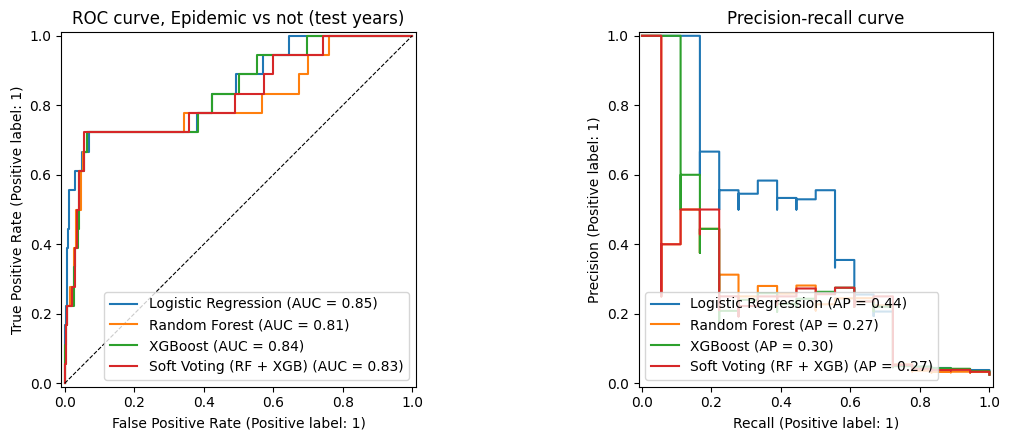

In [54]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, pipe in fitted_binary.items():
    proba = pipe.predict_proba(X_test)[:, 1]
    RocCurveDisplay.from_predictions(yb_test, proba, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(yb_test, proba, name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], "k--", linewidth=0.8)
axes[0].set_title("ROC curve, Epidemic vs not (test years)")
axes[1].set_title("Precision-recall curve")
plt.tight_layout()
plt.show()

In [55]:
vote_pred = (fitted_binary["Soft Voting (RF + XGB)"].predict_proba(X_test)[:, 1] >= 0.5).astype(int)
tn, fp, fn, tp = confusion_matrix(yb_test, vote_pred, labels=[0, 1]).ravel()
print("Soft voting, Epidemic alarm on the test years:")
print(f"  True positives  (Epidemic, alarm raised):     {tp}")
print(f"  False negatives (Epidemic, missed):           {fn}")
print(f"  False positives (normal month, false alarm):  {fp}")
print(f"  True negatives  (normal month, no alarm):     {tn}")

Soft voting, Epidemic alarm on the test years:
  True positives  (Epidemic, alarm raised):     13
  False negatives (Epidemic, missed):           5
  False positives (normal month, false alarm):  39
  True negatives  (normal month, no alarm):     667


With only 2.5% of test months being Epidemic, a random guess would get a PR-AUC of 0.025. Every model ranks Epidemic months far above normal ones (ROC-AUC 0.81-0.85, PR-AUC 0.27-0.45). As with the 3-class task, **Logistic Regression ranks best** (ROC-AUC 0.849, PR-AUC 0.445).

At the default 0.5 threshold, though, the models behave very differently:

- **Logistic Regression** with balanced class weights catches 13 of 18 (sensitivity 0.72) but raises 119 alarms, so its specificity drops to 0.85 and only 11% of its alarms are real.
- **XGBoost** with `scale_pos_weight=6.44` also catches 13 of 18 with 87 alarms. The weight was set from the training years, where 13% of months were Epidemic, so it overcorrects for test years where the real rate is about 2.5%.
- **Random Forest** with balanced subsamples is the most conservative: 34 alarms, specificity 0.965, but it catches only half the Epidemic months.
- **Soft voting** keeps the 0.72 sensitivity with only 52 alarms (specificity 0.945), giving the best F1 (0.371) and the best balanced accuracy (0.833).

In confusion-matrix terms, the voting alarm got 13 true positives, 5 false negatives (missed Epidemic months), 39 false positives and 667 true negatives.

Which balance is right depends on what each mistake costs. A missed outbreak means delayed fogging and overcrowded wards; a false alarm means an extra inspection round. High sensitivity with a manageable number of alarms is the sensible target, which is what voting gives at the default threshold. Logistic Regression's better ranking (PR-AUC) suggests it could do even better with a tuned threshold, but tuning a threshold properly needs its own validation year, so it is left as an improvement.

**Calibration.** If the alarm says "30% chance of Epidemic", roughly 30% of such months should really be Epidemic. Class weighting pushes probabilities up on purpose, so this is worth checking before anyone reads the probability at face value. The Brier score (mean squared error of the probabilities, lower is better) is shown alongside.

Logistic Regression       Brier score = 0.1183 | mean predicted = 0.264 vs actual rate = 0.025
Random Forest             Brier score = 0.0534 | mean predicted = 0.168 vs actual rate = 0.025
Soft Voting (RF + XGB)    Brier score = 0.0706 | mean predicted = 0.206 vs actual rate = 0.025


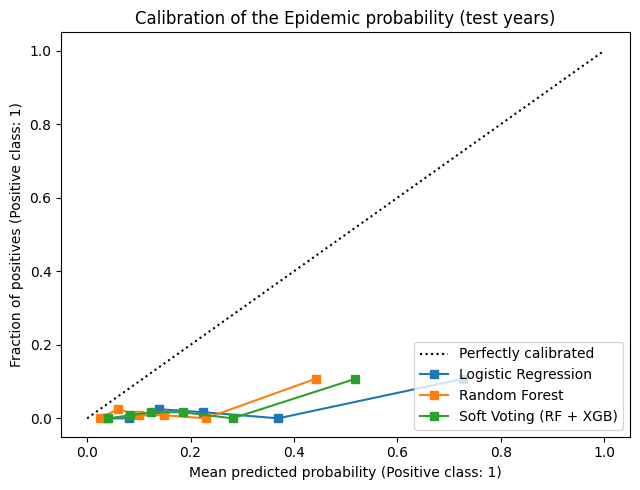

In [56]:
from sklearn.calibration import CalibrationDisplay
from sklearn.metrics import brier_score_loss

fig, ax = plt.subplots(figsize=(6.5, 5))
for name in ["Logistic Regression", "Random Forest", "Soft Voting (RF + XGB)"]:
    proba = fitted_binary[name].predict_proba(X_test)[:, 1]
    CalibrationDisplay.from_predictions(yb_test, proba, n_bins=6, strategy="quantile", name=name, ax=ax)
    print(f"{name:25s} Brier score = {brier_score_loss(yb_test, proba):.4f} | mean predicted = {proba.mean():.3f} vs actual rate = {yb_test.mean():.3f}")
ax.set_title("Calibration of the Epidemic probability (test years)")
plt.tight_layout()
plt.show()

The probabilities are **not calibrated**. Only 2.5% of test months were Epidemic, but the models' average predicted probability is 17-26%. Two things push them up: the class weighting (deliberately), and the much higher Epidemic rate in the training years (13%, mostly 2017). Random Forest is the least overconfident (Brier score 0.053), soft voting is next (0.071), and Logistic Regression with balanced weights is the most inflated (0.118).

In practice, the Epidemic number should be read as a **risk score for ranking and alarms**, not a literal probability, and the dashboard says so. Recalibrating on a recent validation year (for example with `CalibratedClassifierCV`) would be the fix, and it is left as an improvement.

## <center><b>9. Third Task: How Many Cases?</b></center>

Regression parameters follow the same reasoning as Section 6, with these changes:

- **Decision Tree (weak learner):** `max_depth=6`, `min_samples_leaf=10`, so each leaf's prediction is an average over at least 10 district-months.
- **Random Forest:** Breiman's recommendations for regression forests are `m = p/3` features per split and a minimum node size of 5, so `max_features=1/3` and `min_samples_leaf=5`. `max_depth=12` (deeper than the classifier) so the trees can produce a range of different numbers instead of a few averaged steps.
- **XGBoost:** `objective="count:poisson"`. Case counts are non-negative whole numbers whose spread grows with their size (a district averaging 600 cases swings by hundreds, one averaging 10 by a handful), which is exactly what a Poisson model assumes. It predicts on a log scale internally, so it can never predict negative cases. The number of trees comes from early stopping on 2023 again.

Two baselines: **last month's count** (the simplest possible forecast), and the district's training-years average.

In [57]:
yr_train, yr_test = train_df["cases"], test_df["cases"]

rf_reg_params = dict(n_estimators=500, criterion="squared_error", max_depth=12, min_samples_split=10, min_samples_leaf=5,
                     max_features=1 / 3, max_samples=0.8, bootstrap=True, oob_score=True, n_jobs=-1, random_state=random_state)

xgb_reg_search = XGBRegressor(n_estimators=3000, objective="count:poisson", eval_metric="poisson-nloglik",
                              early_stopping_rounds=50, **xgb_shared_params)
xgb_reg_search.fit(es_prep.transform(fit_part[feature_columns]), fit_part["cases"],
                   eval_set=[(es_prep.transform(val_part[feature_columns]), val_part["cases"])], verbose=False)
xgb_reg_n_estimators = xgb_reg_search.best_iteration + 1
print("Best number of trees (Poisson regression):", xgb_reg_n_estimators)

xgb_reg_params = dict(n_estimators=xgb_reg_n_estimators, objective="count:poisson", **xgb_shared_params)

Best number of trees (Poisson regression): 231


In [58]:
regressors = {
    "Decision Tree": DecisionTreeRegressor(max_depth=6, min_samples_split=20, min_samples_leaf=10, random_state=random_state),
    "Random Forest": RandomForestRegressor(**rf_reg_params),
    "XGBoost (Poisson)": XGBRegressor(**xgb_reg_params),
}
regressors["Voting (average of RF + XGB)"] = VotingRegressor(
    [("rf", clone(regressors["Random Forest"])), ("xgb", clone(regressors["XGBoost (Poisson)"]))])
regressors["Stacking (RF + XGB -> Ridge)"] = StackingRegressor(
    [("rf", clone(regressors["Random Forest"])), ("xgb", clone(regressors["XGBoost (Poisson)"]))],
    final_estimator=Ridge(alpha=1.0), cv=KFold(n_splits=5, shuffle=False))


def regression_scores(name, y_true, y_pred, y_train_true=None, y_train_pred=None):
    return {
        "Model": name,
        "Train R2": r2_score(y_train_true, y_train_pred) if y_train_true is not None else np.nan,
        "Test MAE": mean_absolute_error(y_true, y_pred),
        "Test RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "Test R2": r2_score(y_true, y_pred),
    }


last_month = test_df["prev_month_incidence"].fillna(test_df["rolling_3month_avg"])
district_avg = test_df["district"].map(train_df.groupby("district")["cases"].mean())
reg_rows = [
    regression_scores("Baseline: last month's cases", yr_test, last_month),
    regression_scores("Baseline: district average", yr_test, district_avg),
]

fitted_regressors = {}
for name, model in regressors.items():
    pipe = Pipeline([("prep", build_preprocessor()), ("model", model)]).fit(X_train, yr_train)
    fitted_regressors[name] = pipe
    reg_rows.append(regression_scores(name, yr_test, pipe.predict(X_test), yr_train, pipe.predict(X_train)))

regression_results = pd.DataFrame(reg_rows)
regression_results.round(3)

,Model,Train R2,Test MAE,Test RMSE,Test R2
0,Baseline: last month's cases,NaN,60.949,132.361,0.756
1,Baseline: district average,NaN,86.025,161.595,0.636
2,Decision Tree,0.670,78.559,168.653,0.603
3,Random Forest,0.751,60.034,116.279,0.811
4,XGBoost (Poisson),0.890,57.979,113.164,0.821
5,Voting (average of RF + XGB),0.838,57.436,112.373,0.824
6,Stacking (RF + XGB -> Ridge),0.867,76.733,145.522,0.704


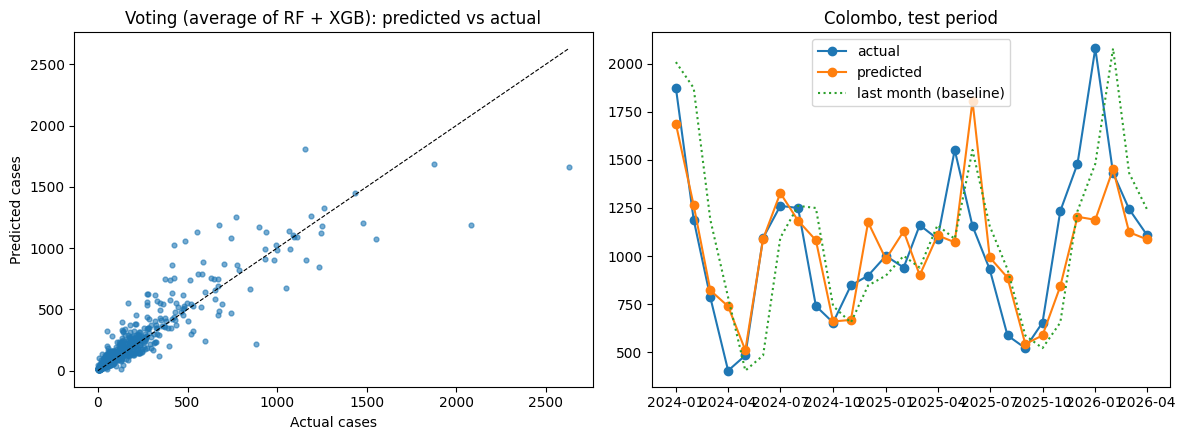

In [59]:
best_reg_name = "Voting (average of RF + XGB)"
reg_pred = fitted_regressors[best_reg_name].predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(yr_test, reg_pred, s=12, alpha=0.6)
lim = max(yr_test.max(), reg_pred.max())
axes[0].plot([0, lim], [0, lim], "k--", linewidth=0.8)
axes[0].set_xlabel("Actual cases")
axes[0].set_ylabel("Predicted cases")
axes[0].set_title(f"{best_reg_name}: predicted vs actual")

colombo = test_df["district"] == "Colombo"
months = pd.to_datetime(test_df.loc[colombo, ["year", "month"]].assign(day=1))
axes[1].plot(months, yr_test[colombo], marker="o", label="actual")
axes[1].plot(months, reg_pred[colombo.values], marker="o", label="predicted")
axes[1].plot(months, last_month[colombo], linestyle=":", label="last month (baseline)")
axes[1].set_title("Colombo, test period")
axes[1].legend()
plt.tight_layout()
plt.show()

The first baseline is the number to beat. Just predicting "same as last month" already gets an MAE of about 61 cases and R² of 0.76, because dengue counts change gradually most of the time.

- The **Decision Tree** (weak learner) is worse than that baseline (MAE 78.6, R² 0.60). A single tree with 10-row leaves can only predict a limited set of averaged values.
- **Random Forest**, with Breiman's regression settings (`m = p/3`, leaf size 5), gets MAE 60.0 and R² 0.811. Its training R² (0.75) is now *lower* than its test R², so these settings removed the overfitting completely.
- **XGBoost (Poisson)** gets MAE 58.0 and R² 0.821, and **voting** is the best overall (MAE 57.4, RMSE 112.4, R² 0.824).
- **Stacking** is again the worst ensemble (MAE 76.7), for the same reason as in classification.

So the ensembles beat the obvious forecast, but modestly. The bigger improvement is in RMSE (132 down to 112), which punishes large misses, so the models help most during the sharp rises and falls that last month's number can't anticipate. The Colombo chart shows this: the baseline is always one step behind, while the prediction often moves at the same time as the actual count.

The scatter plot shows the main limitation: the largest months (far right) sit below the line. Tree models average over values they have seen in training, so they cannot predict beyond that range, and they underestimate the peaks of new outbreaks.

## <center><b>10. What the Models Are Using</b></center>

Four views of the 3-class models:

1. **Built-in (impurity) importance** from Random Forest. Quick, but known to favour continuous and high-cardinality columns.
2. **Permutation importance** on the test set: shuffle one feature and measure how much macro F1 drops. Slower, but measures what actually matters on unseen data.
3. **SHAP values** for XGBoost, which show how much a feature matters and in which direction it pushes the Epidemic prediction.
4. **Partial dependence plots**, as used by Fan et al. (2025): how the predicted Epidemic probability changes as one feature changes, averaged over everything else.

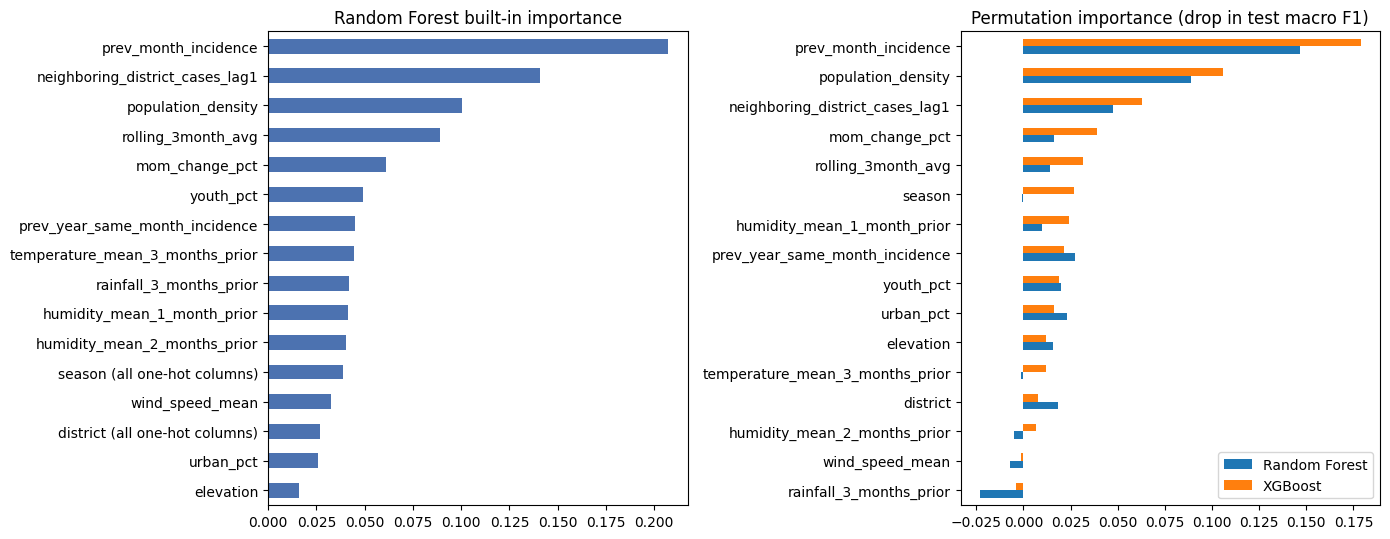

In [60]:
feature_names = fitted_classifiers["Random Forest"].named_steps["prep"].get_feature_names_out()
feature_names = [n.split("__", 1)[1] for n in feature_names]

impurity = pd.Series(fitted_classifiers["Random Forest"].named_steps["model"].feature_importances_, index=feature_names)
# group the one-hot district columns back into one number so they can be compared fairly
impurity_grouped = impurity.groupby(lambda n: "district (all one-hot columns)" if n.startswith("district_")
                                    else ("season (all one-hot columns)" if n.startswith("season_") else n)).sum()

perm_rows = {}
for name in ["Random Forest", "XGBoost"]:
    perm = permutation_importance(fitted_classifiers[name], X_test, y_test, scoring="f1_macro",
                                  n_repeats=10, random_state=random_state, n_jobs=-1)
    perm_rows[name] = pd.Series(perm.importances_mean, index=feature_columns)
perm_table = pd.DataFrame(perm_rows)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
impurity_grouped.sort_values().plot(kind="barh", ax=axes[0], color="#4C72B0")
axes[0].set_title("Random Forest built-in importance")
perm_table.sort_values("XGBoost").plot(kind="barh", ax=axes[1])
axes[1].set_title("Permutation importance (drop in test macro F1)")
plt.tight_layout()
plt.show()

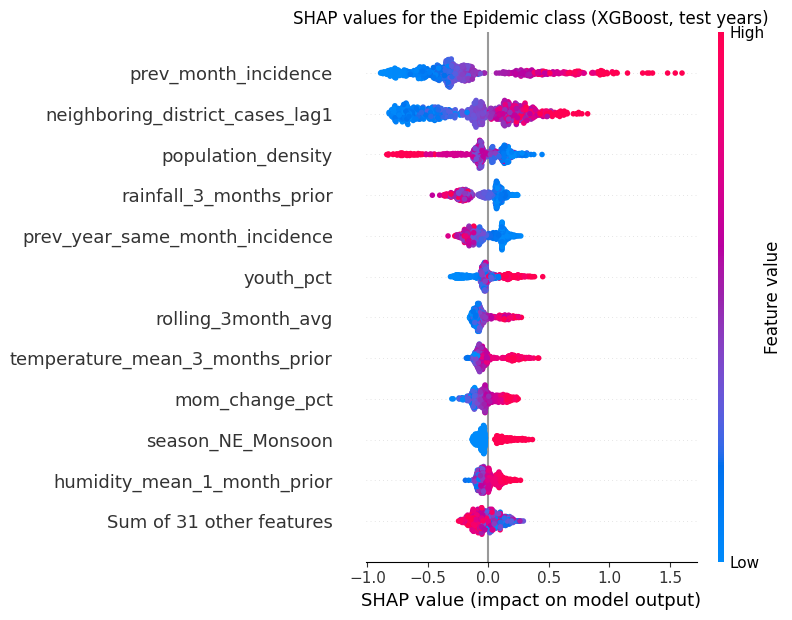

In [61]:
xgb_fitted = fitted_classifiers["XGBoost"]
X_test_prepared = pd.DataFrame(xgb_fitted.named_steps["prep"].transform(X_test), columns=feature_names)

explainer = shap.TreeExplainer(xgb_fitted.named_steps["model"])
shap_values = explainer(X_test_prepared)

# class index 2 = Epidemic
shap.plots.beeswarm(shap_values[:, :, 2], max_display=12, show=False)
plt.title("SHAP values for the Epidemic class (XGBoost, test years)")
plt.tight_layout()
plt.show()

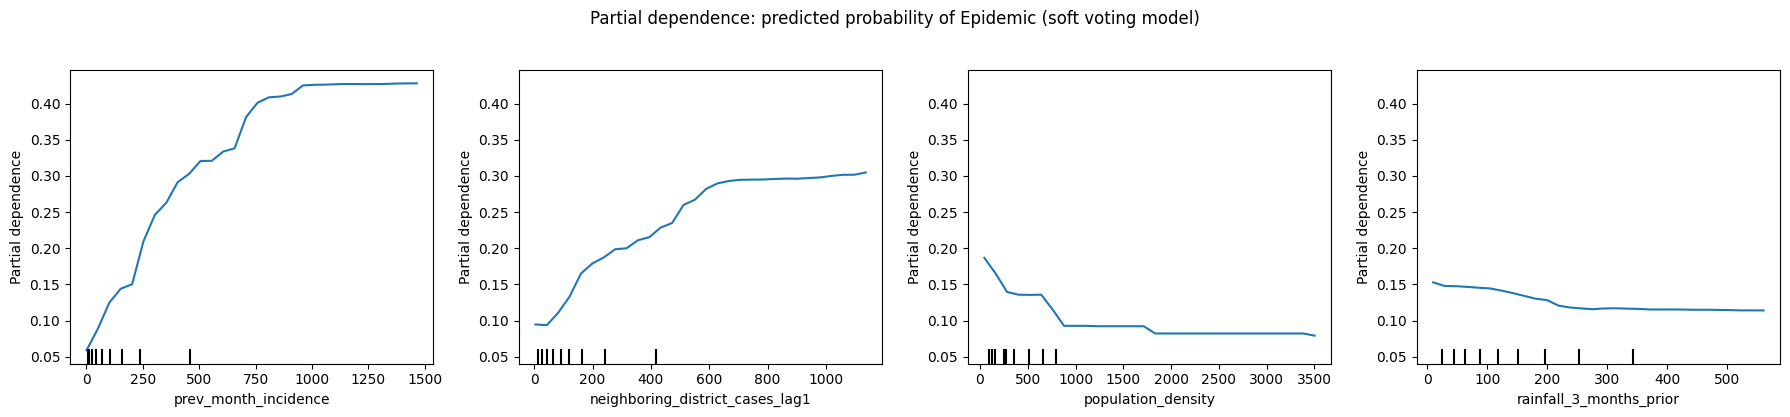

In [62]:
pdp_features = ["prev_month_incidence", "neighboring_district_cases_lag1", "population_density", "rainfall_3_months_prior"]
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
# rows with all four features present, since the plot grid is built from their percentiles
pdp_rows = X_train.dropna(subset=pdp_features)
PartialDependenceDisplay.from_estimator(
    fitted_classifiers["Soft Voting (RF + XGB)"], pdp_rows, pdp_features, target=2, kind="average",
    grid_resolution=30, percentiles=(0.02, 0.98), ax=ax,
)
fig.suptitle("Partial dependence: predicted probability of Epidemic (soft voting model)", y=1.03)
plt.tight_layout()
plt.show()

All four views agree on what matters most:

1. **prev_month_incidence (last month's cases)** is the strongest predictor by far, and it was also the decision tree's very first split (6.1). Dengue has momentum: last month's mosquito population and infected people are still around this month. The partial dependence plot shows the Epidemic probability climbing steeply from about 6% to 43% as last month's count rises to around 1,000 cases, then flattening. The flat part is the tree models not being able to extrapolate beyond the range of the training data.
2. **neighboring_district_cases_lag1**: what was happening next door last month. Dengue moves between districts with people (commuting, travel), so an outbreak in Gampaha is a warning sign for Colombo and vice versa. Its partial dependence rises from about 9% to 30%.
3. **population_density** works in the opposite direction from what you might expect: higher density pushes *away* from Epidemic (partial dependence falls from about 19% to 8%, and the SHAP plot shows the same). This comes from how the label is defined. Colombo and other dense districts always have a lot of cases, so their own threshold (mean + 2 SD) is very high and hard to exceed. A rural district with a quiet baseline can jump into Epidemic territory much more easily. The models have learned something about the label method, not just about dengue.

Other points:

- High **prev_year_same_month_incidence** lowers the Epidemic risk in the SHAP plot. One explanation is short-term immunity after a big outbreak, which fits 2018 being quiet after 2017. It could also be the label again, since a big year raises the next year's baseline.
- The **NE_Monsoon** season (December to February) pushes towards Epidemic, matching the usual year-end peak in Sri Lanka.
- **rainfall_3_months_prior** has only a small effect: the Epidemic probability drifts down from about 15% to 12% as rainfall goes from 0 to about 250 mm, then stays flat. Heavy rain can flush out breeding sites, and rainfall is also tangled up with season, so this shouldn't be read as "more rain means less dengue".

Overall, weather matters much less than case history, and in permutation importance on the test years rainfall and wind speed even come out slightly negative for Random Forest (shuffling them made the score marginally better). The built-in importance ranks rainfall well above zero, which shows the known bias of impurity importance towards continuous features.

## <center><b>11. Strengths, Limitations and an Existing Approach</b></center>

### <b>11.1 Strengths and Limitations</b>

These points are based on what happened in this notebook, not just general theory.

| Model | Strengths (seen here) | Limitations (seen here) |
|---|---|---|
| **Decision Tree** (weak learner) | Fully interpretable: the top splits (last month's cases, then neighbours, then density) can be read directly. Fast. Settings are easy to tune with a grid search and pruning. | Clear ceiling around 0.46-0.50 macro F1 however it is tuned. Unpruned it memorises (437 leaves, training F1 = 1.00). Unstable; small changes in data give a different tree. Worst learned model on every task, and worse than "same as last month" for case counts. |
| **Logistic Regression** (weak learner) | Best model on the test years for the 3-class task (macro F1 0.621) and the best ranking for the Epidemic alarm (PR-AUC 0.445). Tiny train-test gap (low variance). Interpretable coefficients. | Middle of the pack in cross-validation, so its test lead may be specific to the quiet 2024-2026 period (McNemar p = 0.34 against voting). Assumes a (log-)linear relationship, so it can't capture district x season interactions. With balanced weights it raises far too many alarms at the 0.5 threshold (119). |
| **Bagging** | Reduces the single tree's variance a lot (macro F1 0.571 vs 0.461 on test). Simple, with the lowest fold-to-fold spread in cross-validation. | All trees see the same strong columns, so they are correlated. Largest train-test gap (0.17). Slightly behind Random Forest in cross-validation. |
| **Random Forest** | Very stable. More trees never hurt (OOB curve flattens after ~100 trees). OOB score is a free, honest validation estimate (0.714 vs 0.696 on test). Breiman's regression settings removed overfitting completely for case counts. | Still overfits the 3-class task even with limits on depth and leaf size (gap 0.16). Leans towards the Warning class. Largest model file. Built-in importance can mislead. Can't predict beyond the training range. |
| **XGBoost** | Best tree-based model on test for the 3-class task. Regularisation (L1/L2, gamma, subsampling) plus early stopping kept its train-test gap the smallest of the tree ensembles. The Poisson objective suits case counts. `scale_pos_weight` gives direct control over class balance. | Many interacting settings, and the right number of trees depends on the learning rate and depth. Would overfit without early stopping (training loss kept falling). `scale_pos_weight` set from training years overcorrected on quieter test years (87 alarms). |
| **Soft voting** | Never the worst, close to the best on every task. Best balance of sensitivity and number of alarms for the Epidemic alarm, and best for case counts. Doesn't rely on one model happening to suit the test years. | Can't add much when its two members make the same mistakes (RF and XGB agreed on 92% of test months). Twice the training and prediction cost. Harder to explain than one model. |
| **Stacking** | Best in cross-validation. In principle it learns how much to trust each model instead of a fixed 50/50. | Worst ensemble on test for both classification and regression. The meta-model needs enough varied data to learn stable weights, and 9 very different years (including 2017) aren't enough. scikit-learn needs folds covering every training row, which forces a time-blocked KFold where earlier blocks are predicted by models that saw later years. |

**Limitations of the whole approach:**

- Only 18 Epidemic months in the test period, so Epidemic metrics are very noisy.
- The test years (2024-2026) are quieter than the training years, which favours low-variance models and makes it hard to judge how the models would do in the next 2017.
- The Endemic Channel label assumes cases are roughly normally distributed, which they aren't (heavy right skew, 3.4), and Section 10 shows the models partly learn quirks of the label (population density).
- Monthly, district-level data can average away a local outbreak in one MOH area.
- Reporting itself changed during COVID-19 (2020-2021), so some low counts in those years reflect less testing rather than less dengue.

### <b>11.2 Comparison with an Existing Approach</b>

A recent study (Fan et al., 2025, *Frontiers in Artificial Intelligence*) compared XGBoost, Random Forest and Logistic Regression on hospital data. Their setup: a random 80/20 split, SMOTE oversampling inside the training pipeline, XGBoost with `max_depth=5, learning_rate=0.1, n_estimators=200`, Random Forest with `n_estimators=200, max_depth=5`, and Logistic Regression with default settings. That approach is reproduced here on the dengue data, first exactly as published (random split), then on the same time-based split used in this notebook, so it can be compared fairly with the models above.

In [63]:
paper_models = {
    "Paper: Logistic Regression (defaults)": LogisticRegression(random_state=random_state),
    "Paper: Random Forest (200 trees, depth 5)": RandomForestClassifier(n_estimators=200, max_depth=5, random_state=random_state),
    "Paper: XGBoost (depth 5, lr 0.1, 200 trees)": XGBClassifier(max_depth=5, learning_rate=0.1, n_estimators=200,
                                                                eval_metric="mlogloss", random_state=random_state),
}


def paper_pipeline(model):
    return ImbPipeline([("prep", build_preprocessor()), ("smote", SMOTE(sampling_strategy="auto", random_state=42)), ("model", model)])


all_X, all_y = df[feature_columns], df["zone"]
Xr_train, Xr_test, yr_train_rand, yr_test_rand = train_test_split(all_X, all_y, test_size=0.2, random_state=42, stratify=all_y)

paper_rows = []
for name, model in paper_models.items():
    random_fit = paper_pipeline(clone(model)).fit(Xr_train, yr_train_rand)
    time_fit = paper_pipeline(clone(model)).fit(X_train, y_train)
    paper_rows.append({
        "Model": name,
        "Random split accuracy": accuracy_score(yr_test_rand, random_fit.predict(Xr_test)),
        "Random split macro F1": f1_score(yr_test_rand, random_fit.predict(Xr_test), average="macro"),
        "Time split accuracy": accuracy_score(y_test, time_fit.predict(X_test)),
        "Time split macro F1": f1_score(y_test, time_fit.predict(X_test), average="macro"),
        "Time split Epidemic recall": recall_score(y_test, time_fit.predict(X_test), labels=[2], average="macro", zero_division=0),
    })

ours = test_results.set_index("Model")
for name in ["Random Forest", "XGBoost", "Soft Voting (RF + XGB)"]:
    paper_rows.append({
        "Model": f"This notebook: {name}",
        "Time split accuracy": ours.loc[name, "Test accuracy"],
        "Time split macro F1": ours.loc[name, "Test macro F1"],
        "Time split Epidemic recall": ours.loc[name, "Epidemic recall"],
    })
paper_comparison = pd.DataFrame(paper_rows)
paper_comparison.round(3)

,Model,Random split accuracy,Random split macro F1,Time split accuracy,Time split macro F1,Time split Epidemic recall
0,Paper: Logistic Regression (defaults),0.686,0.649,0.651,0.547,0.722
1,"Paper: Random Forest (200 trees, depth 5)",0.685,0.648,0.588,0.477,0.611
2,"Paper: XGBoost (depth 5, lr 0.1, 200 trees)",0.739,0.721,0.659,0.545,0.500
3,This notebook: Random Forest,NaN,NaN,0.696,0.553,0.222
4,This notebook: XGBoost,NaN,NaN,0.702,0.581,0.278
5,This notebook: Soft Voting (RF + XGB),NaN,NaN,0.693,0.559,0.222


Three things stand out:

1. **The random split makes everything look better.** The paper's XGBoost reaches 73.9% accuracy (macro F1 0.72) with a random 80/20 split, but only 65.9% (0.55) on the time-based split. With a random split, neighbouring months from the same district and the same outbreak land on both sides of the split, and the lag features overlap, so the test set isn't really "unseen". For hospital records that are independent patients this may be fine, but for a time series like this one it is train-test contamination.
2. **On a fair (time-based) split, the designed models in this notebook do better** on accuracy and macro F1: 69-70% and 0.55-0.58 here, against 59-66% and 0.48-0.55 for the paper's settings. The paper's Random Forest with `max_depth=5` underfits this data (58.8%), and its untuned XGBoost (learning rate 0.1, 200 trees, no early stopping) is behind the regularised version used here.
3. **SMOTE trades accuracy for Epidemic recall.** With synthetic Epidemic rows, the paper's models catch far more Epidemic months (recall 0.50-0.72 against 0.22-0.28 here), but they lose 4-11 points of accuracy because they also call many normal months Epidemic. This is the same trade-off as the class weighting in Section 8, done with synthetic rows instead of weights. For a health office, which side to favour is a policy decision.

(The paper also set `scale_pos_weight=10`; that only applies to binary XGBoost, so it isn't used in this 3-class reproduction.)

## <center><b>12. Saving the Model</b></center>

Following the rule in Section 7.1, **soft voting (Random Forest + XGBoost)** is deployed for all three tasks. Cross-validation couldn't separate the main models, and McNemar's test couldn't separate RF from XGBoost, or Logistic Regression from voting. For the Epidemic alarm, voting gave the best balance of sensitivity and number of alarms. For case counts it was the best model. Using the same type of model for all three tasks keeps the app consistent. Logistic Regression was the best single model on the test years and is the main alternative to revisit.

Everything the front end needs goes into one pickle: the fitted pipelines (preprocessing is inside them, so raw values can be passed straight in), the feature lists, the zone names, and per-district reference values (elevation, census figures) so the app can fill those in automatically when a district is chosen.

The models are retrained on **all** labelled data (2015 to 2026, minus the held-out Colombo row) before saving. The test set has done its job of measuring performance; for real use, the model should learn from the most recent years too.

Two extra files are written for the dashboard: **data/model_ready.csv** (the modelling table with all three targets, so models can be retrained live in the app) and **models/results.json** (the result tables from this notebook).

In [64]:
deployed_classifier_name = "Soft Voting (RF + XGB)"
deployed_binary_name = "Soft Voting (RF + XGB)"
deployed_regressor_name = "Voting (average of RF + XGB)"

X_all, y_all, yb_all, yr_all = df[feature_columns], df["zone"], df["is_epidemic"], df["cases"]

ensemble_model = Pipeline([("prep", build_preprocessor()), ("model", clone(classifiers[deployed_classifier_name]))]).fit(X_all, y_all)
final_binary = Pipeline([("prep", build_preprocessor()), ("model", clone(binary_models[deployed_binary_name]))]).fit(X_all, yb_all)
final_regressor = Pipeline([("prep", build_preprocessor()), ("model", clone(regressors[deployed_regressor_name]))]).fit(X_all, yr_all)

district_reference = (df.sort_values(["year", "month"]).groupby("district")
                      [["elevation", "population_density", "urban_pct", "youth_pct"]].last())

model_bundle = {
    "zone_classifier": ensemble_model,
    "epidemic_classifier": final_binary,
    "case_regressor": final_regressor,
    "model_names": {"zone": deployed_classifier_name, "epidemic": deployed_binary_name, "cases": deployed_regressor_name},
    "feature_columns": feature_columns,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "zone_names": zone_names,
    "districts": sorted(df["district"].unique()),
    "seasons": sorted(df["season"].unique()),
    "district_reference": district_reference,
    "rf_params": {k: v for k, v in rf_params.items() if k not in ("n_jobs",)},
    "xgb_params": {k: v for k, v in xgb_params.items() if k not in ("n_jobs",)},
    "trained_on": f"{len(df)} district-months, 2015-{df['year'].max()}",
}

os.makedirs("models", exist_ok=True)
with open("models/model.pkl", "wb") as f:
    pickle.dump(model_bundle, f)

# the held-out row is saved separately so the app can offer it as an example input
holdout_row.to_csv("models/holdout_sample.csv", index=False)

# files for the dashboard
df[["district", "year", "month"] + feature_columns[1:] + ["zone_name", "is_epidemic", "cases"]].to_csv("data/model_ready.csv", index=False)
results_export = {
    "zone_cv": cv_results.round(4).to_dict(orient="records"),
    "zone_test": test_results.round(4).to_dict(orient="records"),
    "epidemic_test": binary_results.round(4).to_dict(orient="records"),
    "cases_test": regression_results.round(4).to_dict(orient="records"),
    "paper_comparison": paper_comparison.round(4).to_dict(orient="records"),
    "rf_importance": impurity_grouped.sort_values(ascending=False).round(4).to_dict(),
    "permutation_importance": perm_table.round(4).to_dict(),
}
with open("models/results.json", "w") as f:
    json.dump(results_export, f, indent=1, default=str)

print("Saved models/model.pkl:", round(os.path.getsize("models/model.pkl") / 1e6, 1), "MB")

Saved models/model.pkl: 40.8 MB


## <center><b>13. Inference on the Held-Out Sample</b></center>

Now the Colombo row from Section 5.2, which no model has seen. To prove the saved file works on its own, the pickle is loaded fresh from disk rather than reusing the objects already in memory, and only the raw input columns are passed in.

In [65]:
with open("models/model.pkl", "rb") as f:
    loaded = pickle.load(f)

sample = holdout_row[loaded["feature_columns"]]
sample.T.rename(columns={sample.index[0]: "input value"})

,input value
district,Colombo
season,SW_Monsoon
rainfall_3_months_prior,124.9
temperature_mean_3_months_prior,26.639
humidity_mean_1_month_prior,77.267
humidity_mean_2_months_prior,73.871
wind_speed_mean,9.684
elevation,9.0
prev_month_incidence,1110.0
prev_year_same_month_incidence,1552.0


In [66]:
zone_proba = loaded["zone_classifier"].predict_proba(sample)[0]
predicted_zone = loaded["zone_names"][int(np.argmax(zone_proba))]
epidemic_proba = loaded["epidemic_classifier"].predict_proba(sample)[0, 1]
predicted_cases = loaded["case_regressor"].predict(sample)[0]

actual = holdout_row.iloc[0]
print(f"District-month: {actual['district']}, {int(actual['year'])}-{int(actual['month']):02d}")
print()
print("Zone probabilities:", {z: round(float(p), 3) for z, p in zip(loaded["zone_names"], zone_proba)})
print(f"Predicted zone:       {predicted_zone:10s} | actual zone:  {actual['zone_name']}")
print(f"Epidemic probability: {epidemic_proba:.3f}      | actual:       {'Epidemic' if actual['is_epidemic'] else 'not Epidemic'}")
print(f"Predicted cases:      {predicted_cases:10.0f} | actual cases: {int(actual['cases'])}")
print(f"(last month's cases were {int(actual['prev_month_incidence'])}; Warning starts above {actual['baseline_mean']:.0f}, "
      f"Epidemic above {actual['baseline_mean'] + 2 * actual['baseline_std']:.0f})")

District-month: Colombo, 2026-05

Zone probabilities: {'Safety': 0.311, 'Warning': 0.599, 'Epidemic': 0.09}
Predicted zone:       Warning    | actual zone:  Safety
Epidemic probability: 0.108      | actual:       not Epidemic
Predicted cases:            1029 | actual cases: 636
(last month's cases were 1110; Warning starts above 766, Epidemic above 2541)


The saved model loads and predicts from raw values on its own, so the pickle is complete. (The same prediction appears in the app when the held-out example is loaded.)

For May 2026 in Colombo the model predicted **Warning** (60% Warning, 31% Safety, 9% Epidemic) and about **1,030 cases**. The real month was **Safety with 636 cases**, so this one is a miss.

The reason is visible in the inputs. April had 1,110 cases and the 3-month average was 1,262, both well above Colombo's Warning line of 766, and the neighbouring districts were also busy. Everything the model can see says "still high", and then cases dropped by about 43% in one month. Nothing in the features can show a drop like that coming in advance: it could have been the end of the April rains, a clean-up campaign, or simply a reporting delay. This is the same weakness seen in the regression chart. The model relies heavily on momentum, so it is slow to react when an outbreak ends suddenly.

It is a reasonable miss though. It isn't a wild prediction: 31% Safety shows the model wasn't confident, and the Epidemic alarm stayed low (0.11), which is correct, since 636 is nowhere near Colombo's Epidemic line of 2,541. One sample can't say much about a model, which is why it was evaluated on 724 test months first. This is a demonstration that the saved model works end to end on a row it has never seen.

## <center><b>14. Front End: Dengue Risk Dashboard</b></center>

The saved model is served through a Streamlit dashboard, **app/app.py**. It has three tabs:

1. **Predict:** a box for every feature (the district's elevation and census values fill in from the pickle); returns the predicted zone with probabilities, the Epidemic alarm probability and the expected case count. There is a button to load the held-out Colombo example.
2. **Train & Compare:** upload a CSV (or use **data/model_ready.csv**), choose the target and the models (Decision Tree, Logistic Regression, Random Forest, XGBoost, soft voting, stacking), adjust the main Random Forest and XGBoost settings, and compare them side by side, with a confusion matrix and the Random Forest feature importance.
3. **Notebook Results:** the result tables from this notebook.

To run it from the project folder:

```
pip install -r requirements.txt
streamlit run app/app.py
```

## <center><b>15. Conclusion</b></center>

Random Forest and XGBoost were built for three dengue prediction tasks on Sri Lankan district data. Every hyperparameter was chosen from what the data looked like, then checked with OOB curves, depth sweeps and a grid search, instead of being left at defaults. They were compared with two weak learners (a decision tree and logistic regression), with plain bagging, with soft voting and stacking, and with the approach from a published paper.

**What the results say:**

- **Zone (Safety / Warning / Epidemic):** the ensembles reach about 69-70% accuracy and macro F1 0.55-0.58, against 51% and 0.32 for the naive baseline. A single decision tree tops out around 0.46-0.50, which is the case for using ensembles at all.
- **Ensembles are not automatically better.** Logistic Regression was the best model on the 2024-2026 test years (macro F1 0.62), helped by low variance in a quiet period. But it is not statistically different from soft voting (McNemar p = 0.34), and it was only mid-table in cross-validation.
- **RF vs XGBoost:** statistically tied (McNemar p = 0.69). XGBoost generalised slightly better (smaller train-test gap) thanks to its regularisation and early stopping. The OOB curve confirmed that 500 trees is plenty for the forest.
- **Epidemic alarm:** ROC-AUC 0.81-0.85, and soft voting caught 13 of 18 Epidemic months with 52 alarms.
- **Case count:** voting reached R² 0.82 and MAE 57 cases, a modest improvement over "same as last month" (R² 0.76, MAE 61).
- **Stacking** looked best in cross-validation but was the worst ensemble on test both times; nine very different years are not enough to learn stable meta-weights.
- **The published approach**, reproduced here, looks better under a random split (73.9%) than it really is on a time-ordered problem (65.9%). SMOTE raises Epidemic recall at a clear cost in accuracy.
- **What drives predictions:** last month's cases and the neighbouring districts' cases, much more than weather. Population density matters mainly because of how the Endemic Channel label is defined.

**Possible improvements:**

- Add a time-series model (ARIMA or SARIMA per district) and combine it with the tree models (a hybrid model), since momentum is the strongest signal.
- Try CatBoost, since **district** and **season** are categorical, and LightGBM.
- Include Logistic Regression in the ensemble (heterogeneous voting or stacking), since it behaves differently from the tree models and did well on the test years.
- Use weekly instead of monthly data, so turning points show up sooner and there are more rows for tuning and stacking.
- Tune the Epidemic alarm threshold to a number of alarms a health office can follow up, using a dedicated validation year.